# Чекпойнт 2. Анализ PlantVillage и PlantDoc

Посмотрим, как устроены оба датасета, сколько в них классов, какие есть ошибки и повторы, чем отличаются фотографии. По результатам подготовим данные для обучения и проверки модели.

## 1. Подготовка данных

Используем два готовых датасета: PlantVillage и PlantDoc. В них фотографии уже разложены по папкам с названиями классов. Например, в PlantVillage папка `Tomato___healthy` содержит снимки здоровых листьев томата. По названию папки код определяет, к какому классу относится каждый снимок.

Сначала проверим, все ли изображения открываются, каких они размеров и сколько примеров есть в каждом классе. Затем найдем повторы и подготовим списки изображений для обучения и проверки модели.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, platform
ROOT = Path.cwd()
assert (ROOT / 'scripts/eda_core.py').exists(), 'Запустите ноутбук из корня проекта'
os.environ['MPLCONFIGDIR'] = str(ROOT / 'tmp/mpl')
sys.path.insert(0, str(ROOT / 'scripts'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from eda_core import build_metadata, validate_splits, PD_MAP, AMBIGUOUS, SEED, numeric_columns
import eda_figures as plots
from embeddings import run as run_embeddings
plots.style()
pd.set_option('display.max_colwidth', 80)
pd.set_option('display.max_rows', 45)
REBUILD_METADATA = False
REBUILD_EMBEDDINGS = False
print('Python:', platform.python_version(), '| seed:', SEED)

Python: 3.12.3 | seed: 42


<a id="data"></a>
## 2. Датасеты

**PlantVillage** содержит фотографии здоровых и больных листьев. Используем цветную версию `color` с [Hugging Face авторов](https://huggingface.co/datasets/mohanty/PlantVillage). Версии `grayscale` и `segmented` получены из тех же снимков, поэтому мы не добавляем их как новые примеры.

**PlantDoc** берем из [этого репозитория для классификации](https://github.com/pratikkayal/PlantDoc-Dataset). Используем готовые папки train и test из репозитория авторов. Анализируем именно эти файлы: их количество и состав могут отличаться от других сборок PlantDoc.

В этих версиях 54 305 изображений PlantVillage и 2 572 PlantDoc. Дальше считаем статистики по фактически загруженным файлам.

In [2]:
sources = json.loads((ROOT / 'data/external/sources.json').read_text())
display(pd.DataFrame(sources).T[['revision', 'license', 'extracted_files']])
df, pairs = build_metadata(force=REBUILD_METADATA)
df = numeric_columns(df)
valid = df[df.error.eq('')].copy()
clean = df[df.split.ne('excluded')].copy()
overview = df.groupby('dataset').agg(images=('image_id','size'), classes=('label','nunique'),
                                      decoded=('error',lambda x: x.eq('').sum()))
overview['usable_after_cleaning'] = clean.groupby('dataset').size()
display(overview)
assert overview.loc['plantvillage','images'] == 54305
assert overview.loc['plantdoc','images'] == 2572

,revision,license,extracted_files
plantdoc,5467f6012d78d1c446145d5f582da6096f852ae8,CC BY 4.0 (authors repository),2581
plantvillage,9e97599868962bd0079b8db4b7f1efa9185fa1e7,CC BY-SA 3.0 (dataset card),54305


,images,classes,decoded,usable_after_cleaning
dataset,,,,
plantdoc,2572,28,2572,2479
plantvillage,54305,38,54305,54236


### 2.1. Баланс классов

Класс задает и культуру, и состояние листа. Например, здоровые листья томата и яблони относятся к разным классам. Ниже посмотрим число снимков в каждом классе и отношение самого большого класса к самому маленькому.

,min,median,max,max/min,largest_class_share_%
dataset,,,,,
plantdoc,2,91.0,191,95.50,7.43
plantvillage,152,1092.5,5507,36.23,10.14


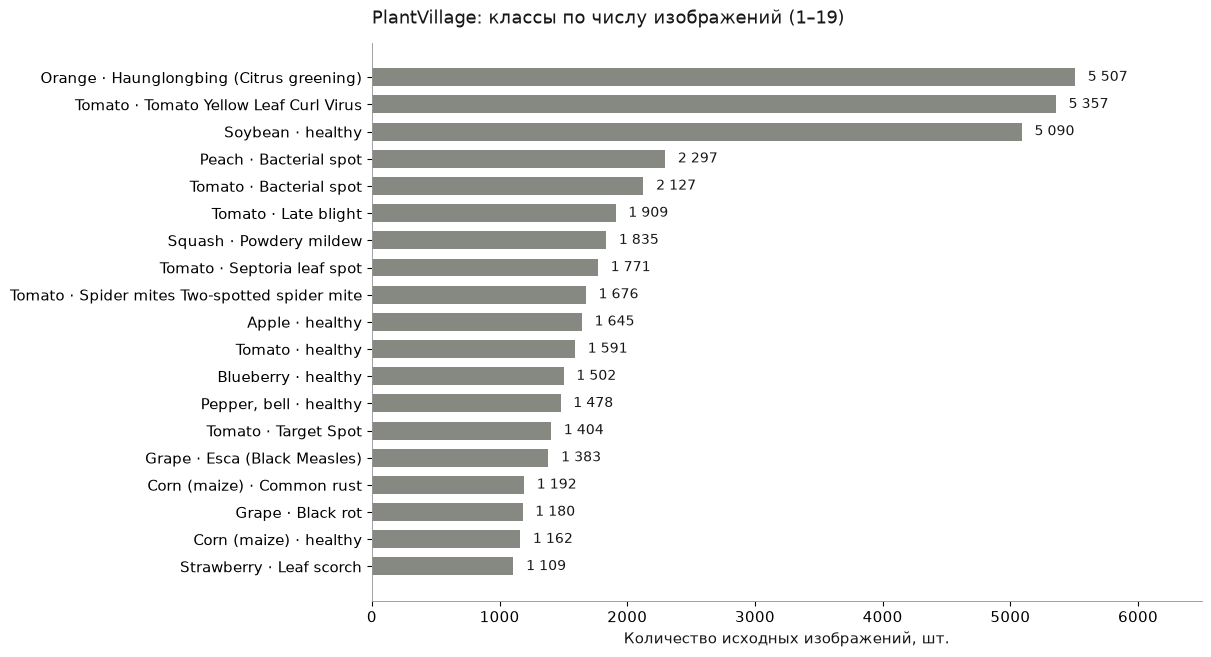

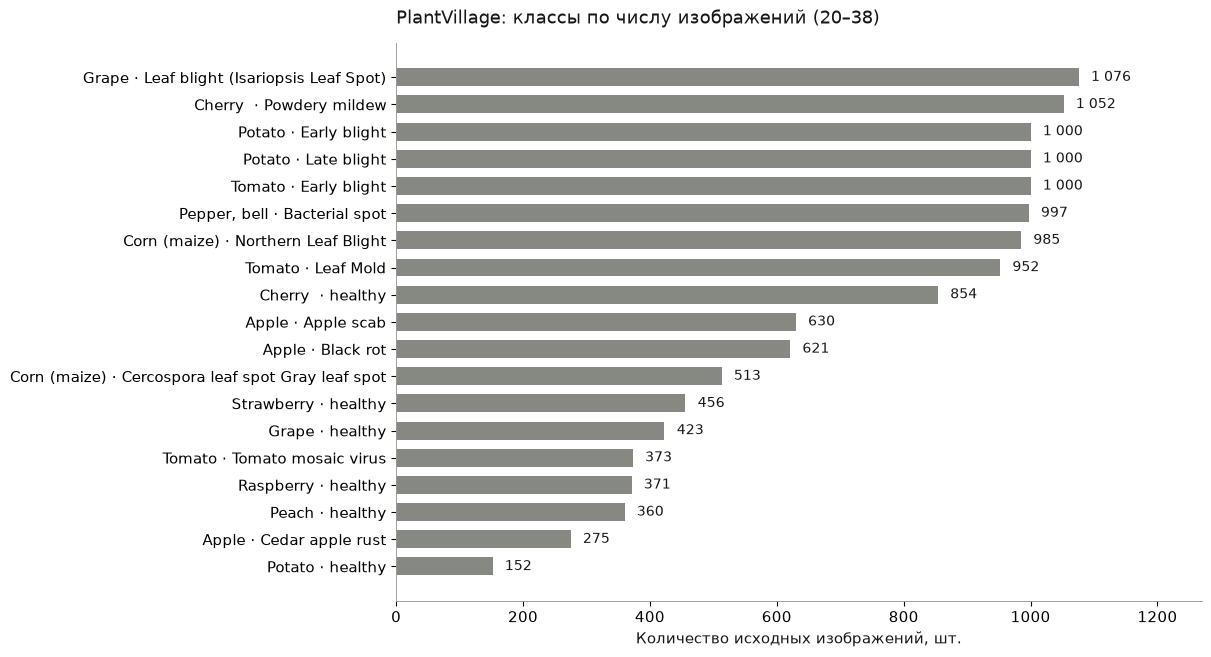

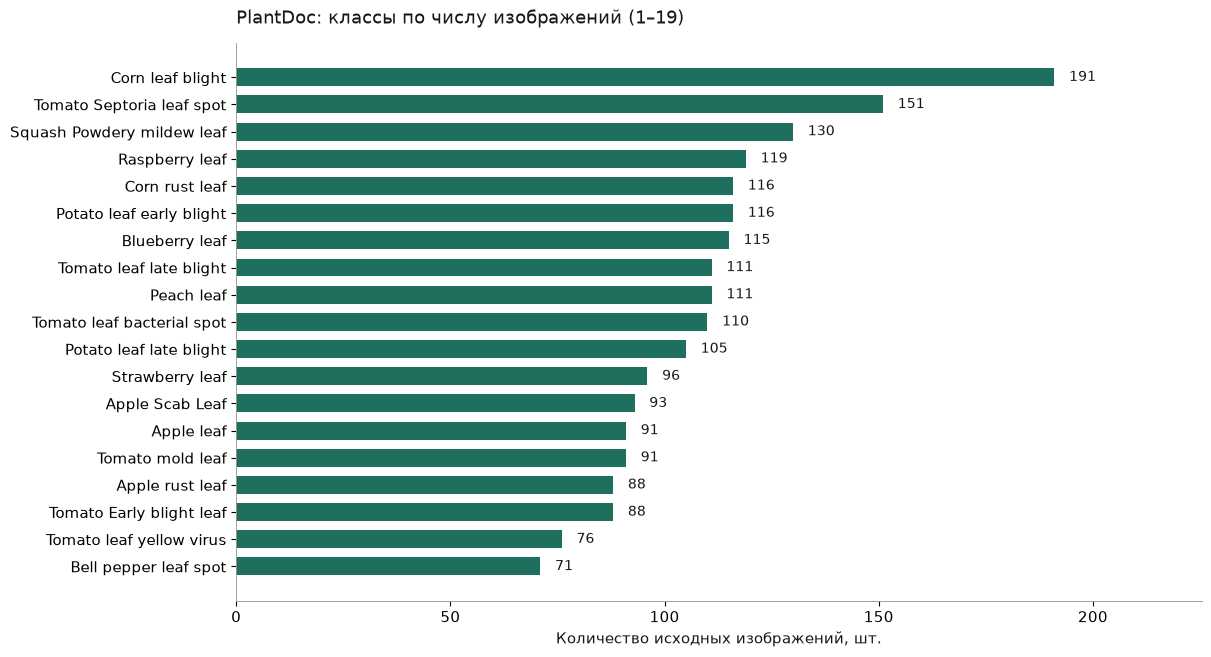

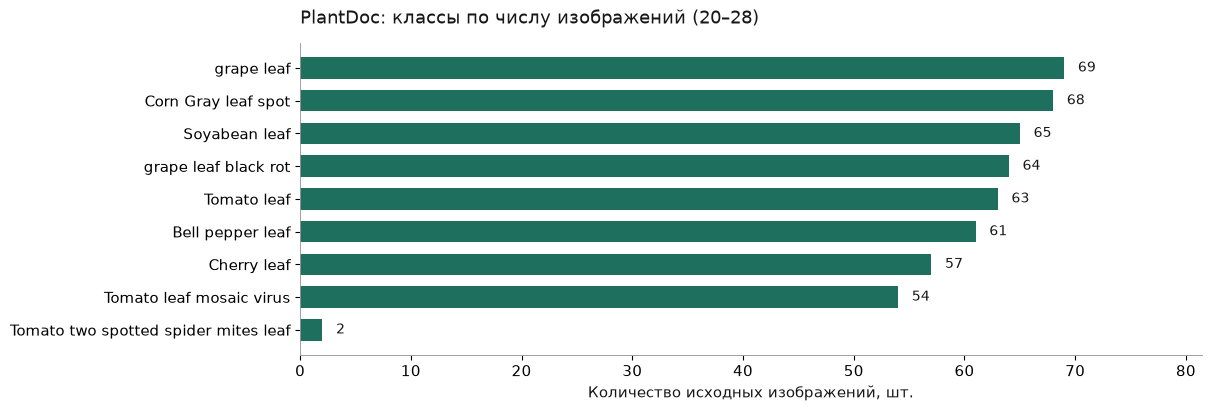

In [3]:
counts = df.groupby(['dataset','label']).size().rename('n').reset_index()
imbalance = counts.groupby('dataset').n.agg(['min','median','max'])
imbalance['max/min'] = imbalance['max'] / imbalance['min']
imbalance['largest_class_share_%'] = 100 * imbalance['max'] / overview.images
display(imbalance.round(2))
counts.to_csv(ROOT / 'reports/class_counts.csv', index=False)
plots.class_counts(df)

В PlantVillage на класс приходится от 152 до 5 507 снимков, разница в 36.2 раза. В PlantDoc разброс еще больше: от 2 до 191, то есть в 95.5 раза. При таком дисбалансе высокая accuracy может скрывать ошибки на редких классах. На следующем этапе мб стоит обсудить macro-F1 и отдельно смотреть recall каждого класса.

У `Tomato two spotted spider mites leaf` всего 2 изображения, оба в исходном train. Проверить качество на этом классе в PlantDoc test не получится. Пока сохраняем все доступные обучающие примеры, взвешенную функцию потерь и сэмплинг мы сравним позже.

### 2.2. Соответствие классов

Названия в датасетах отличаются, поэтому составим таблицу соответствий. Исходные названия тоже сохраняем.

Четыре метки слишком общие: `Apple rust leaf`, `Bell_pepper leaf spot`, `Corn leaf blight`, `Tomato leaf yellow virus`. Для них указали возможные соответствия, но в основное сравнение не включили. Остальные классы сопоставлены по названиям.

В папках PlantDoc здоровые листья названы без слова healthy, например `Apple leaf` и `Tomato leaf`. В [статье авторов, рисунок 2](https://arxiv.org/pdf/1911.10317), соответствующие классы указаны как Apple Healthy и Tomato Healthy. Поэтому сопоставляем их с классами здоровых листьев той же культуры в PlantVillage.

In [4]:
mapping = df[df.dataset.eq('plantdoc')].groupby(['label','canonical_label','mapping_status']).agg(
    raw_n=('image_id','size'), retained_n=('split',lambda s:s.ne('excluded').sum()),
    field_test_n=('split',lambda s:s.eq('field_test').sum()), primary=('common_primary','max')).reset_index()
mapping['note'] = mapping.label.map(AMBIGUOUS).fillna('')
mapping.to_csv(ROOT / 'reports/class_mapping.csv', index=False)
display(mapping[['label','canonical_label','mapping_status','raw_n','field_test_n','primary']])
common_labels = sorted(clean.loc[clean.common_primary, 'canonical_label'].unique())
print('Основное сравнение:', len(common_labels), 'класса')
_ = (ROOT / 'splits/common_classes.json').write_text(json.dumps(common_labels, ensure_ascii=False, indent=2))

,label,canonical_label,mapping_status,raw_n,field_test_n,primary
0,Apple Scab Leaf,Apple___Apple_scab,aligned,93,10,True
1,Apple leaf,Apple___healthy,aligned,91,9,True
2,Apple rust leaf,Apple___Cedar_apple_rust,ambiguous,88,10,False
3,Bell_pepper leaf,"Pepper,_bell___healthy",aligned,61,8,True
4,Bell_pepper leaf spot,"Pepper,_bell___Bacterial_spot",ambiguous,71,9,False
5,Blueberry leaf,Blueberry___healthy,aligned,115,11,True
6,Cherry leaf,Cherry_(including_sour)___healthy,aligned,57,10,True
7,Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,aligned,68,3,True
8,Corn leaf blight,Corn_(maize)___Northern_Leaf_Blight,ambiguous,191,10,False
9,Corn rust leaf,Corn_(maize)___Common_rust_,aligned,116,10,True


Основное сравнение: 23 класса


<a id="quality"></a>
## 3. Форматы, размеры и ошибки

Проверяем каждый файл через `PIL.Image.verify()` и `.load()`: открывается ли он, есть ли метка, какой у него размер и цветовой режим. Перед расчетом признаков учитываем EXIF-ориентацию и приводим изображение к RGB. Исходные файлы сохраняем без изменений.

,decode_errors,missing_labels,missing_mapping,non_RGB,zero_size
dataset,,,,,
plantdoc,0,0,0,11,0
plantvillage,0,0,0,1,0


format       JPEG           MPO  PNG
mode         CMYK  L    RGB RGB RGBA
dataset                             
plantdoc        5  1   2559   2    5
plantvillage    0  0  54304   0    1

width              height              aspect_ratio             
               min median   max    min median   max          min median   max
dataset                                                                      
plantdoc       115  800.0  6000     69  667.0  6000         0.34   1.33  4.75
plantvillage   256  256.0   256    256  256.0   256         1.00   1.00  1.00

,width,height,bytes,brightness,saturation,sharpness
count,56877.0000,56877.0000,5.687700e+04,56877.0000,56877.0000,56877.0000
mean,292.7711,285.6468,3.246223e+04,0.4750,0.2704,0.0154
std,250.4510,210.4399,1.892185e+05,0.0819,0.0945,0.0106
min,115.0000,69.0000,2.885000e+03,0.0324,0.0000,0.0001
25%,256.0000,256.0000,1.244200e+04,0.4262,0.2022,0.0069
50%,256.0000,256.0000,1.625200e+04,0.4703,0.2562,0.0138
75%,256.0000,256.0000,1.945700e+04,0.5146,0.3197,0.0215
max,6000.0000,6000.0000,1.257503e+07,0.9457,0.9475,0.1555


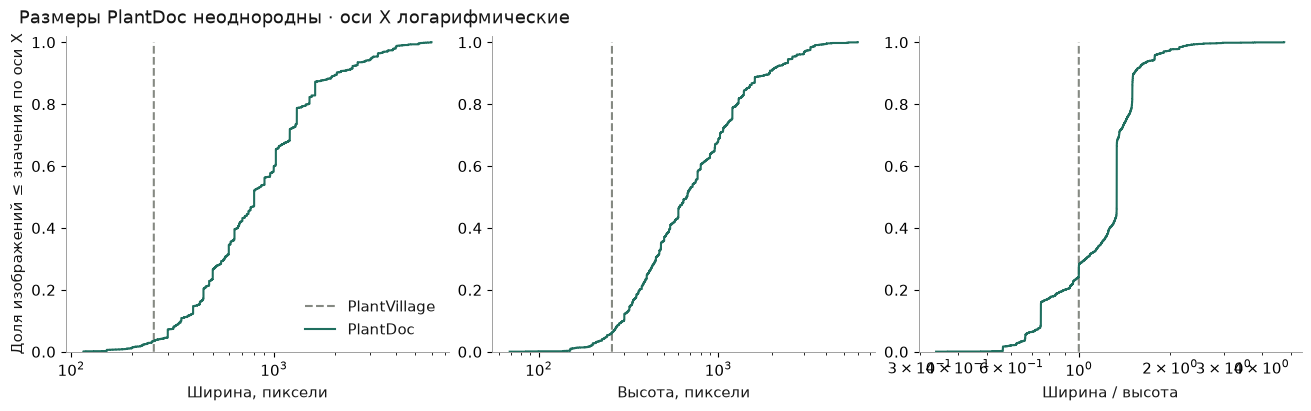

In [5]:
quality = df.groupby('dataset').agg(
    decode_errors=('error',lambda x:x.ne('').sum()),
    missing_labels=('label',lambda x:x.eq('').sum()),
    missing_mapping=('canonical_label',lambda x:x.eq('').sum()),
    non_RGB=('mode',lambda x:x.ne('RGB').sum()),
    zero_size=('bytes',lambda x:x.le(0).sum()))
display(quality)
display(pd.crosstab(df.dataset, [df['format'], df['mode']]))
display(valid.groupby('dataset')[['width','height','aspect_ratio']].agg(['min','median','max']).round(2))
display(valid[['width','height','bytes','brightness','saturation','sharpness']].describe().round(4))
quality.to_csv(ROOT / 'reports/data_quality.csv')
plots.dimension_plots(valid)

Все файлы открылись, пустых меток нет. У PlantVillage есть один снимок в RGBA, у PlantDoc встречаются CMYK, grayscale и RGBA. Поэтому перед подачей в модель нужно приводить изображения к RGB.

У всех фото PlantVillage размер 256×256. У PlantDoc ширина меняется от 115 до 6 000 пикселей, высота от 69 до 6 000, медианы 800 и 667. Их придется приводить к одному размеру, сохраняя пропорции. При обрезке важно не потерять пораженную часть листа.(!)

Для разбиения также нужна инфа о том, какие фотографии показывают один лист. Авторский `leaf_id` нашелся для 40 490 снимков PlantVillage. Для остальных 13 815 использован идентификатор из имени файла. В PlantDoc сведений о растениях и фотосессиях нет. Поэтому полностью исключить попадание связанных снимков в разные части датасета не получится.

n
dataset      leaf_id_source          
plantdoc     not_available       2572
plantvillage author             40490
             filename_fallback  13815

,low_resolution,extreme_aspect,extreme_brightness
dataset,,,
plantdoc,6,1,28
plantvillage,0,0,53


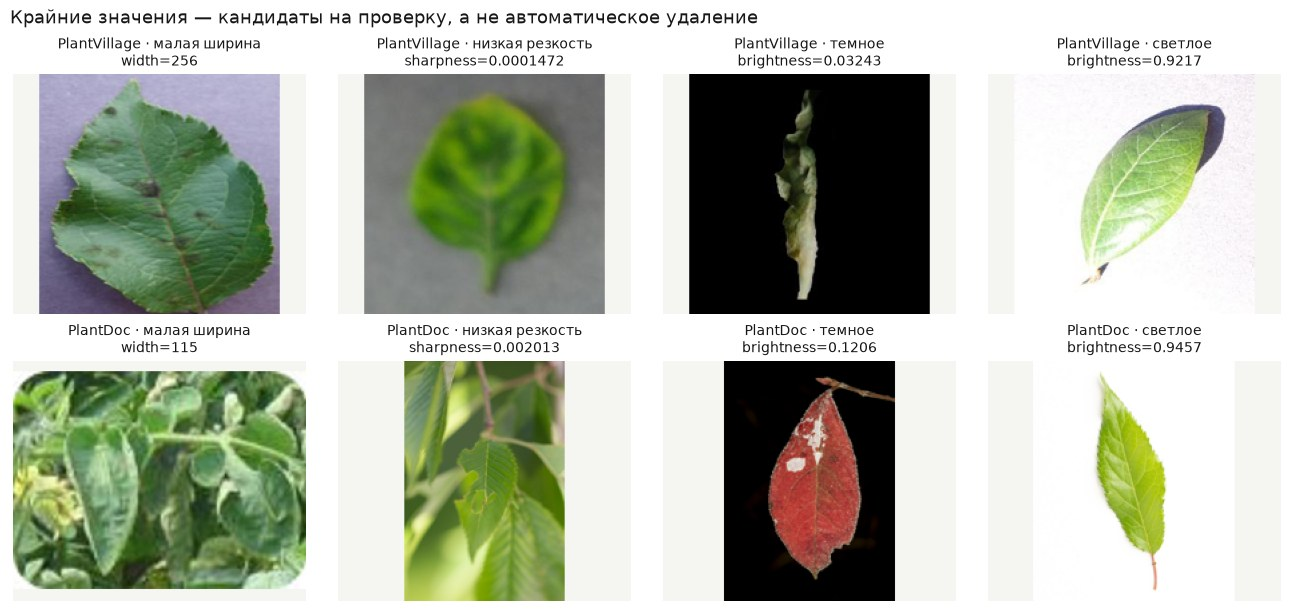

In [6]:
display(df.groupby(['dataset','leaf_id_source']).size().rename('n').to_frame())
# Domain-specific outliers: fixed diagnostic flags, not automatic deletion.
flags = valid.assign(low_resolution=valid[['width','height']].min(axis=1).lt(128),
                     extreme_aspect=(valid.aspect_ratio.lt(.25)|valid.aspect_ratio.gt(4)),
                     extreme_brightness=(valid.brightness.lt(.10)|valid.brightness.gt(.90)))
display(flags.groupby('dataset')[['low_resolution','extreme_aspect','extreme_brightness']].sum())
flagged = flags[flags[['low_resolution','extreme_aspect','extreme_brightness']].any(axis=1)]
flagged[['image_id','path','dataset','label','low_resolution','extreme_aspect','extreme_brightness']].to_csv(
    ROOT / 'reports/quality_flags.csv', index=False)
reviewed_extremes = plots.quality_gallery(valid)

В таблице выше посчитали изображения маленького размера, с сильно вытянутыми пропорциями и очень низкой или высокой яркостью. Список этих фото сохранили в reports/quality_flags.csv. Вообще эти признаки сами по себе не считаем основанием для удаления.

### 3.1. Примеры каждого класса

Выберем по два снимка на класс с фиксированным seed. Этого по идее достаточно, чтобы увидеть характерные объекты и фон, но не чтобы проверить всю разметку)

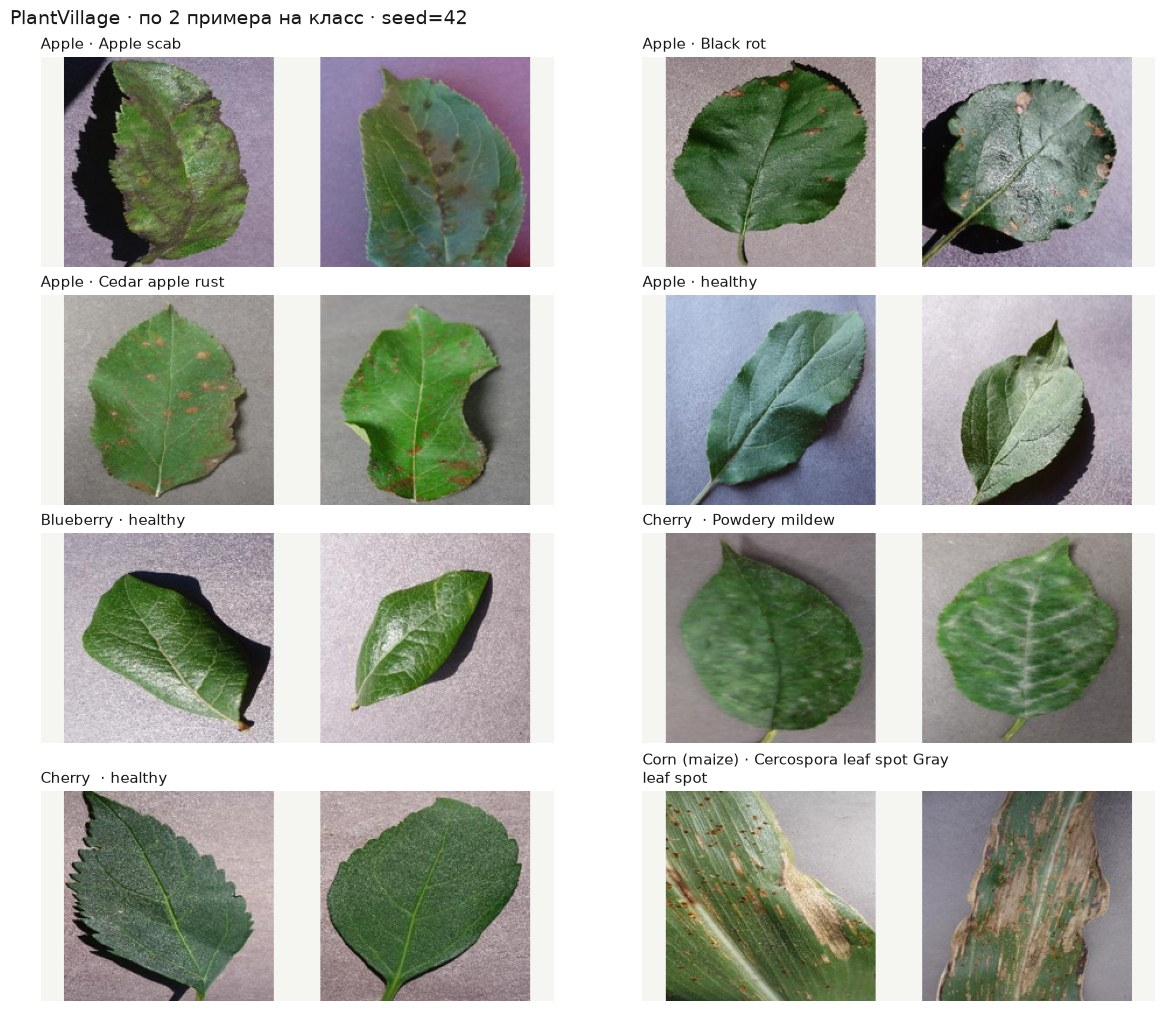

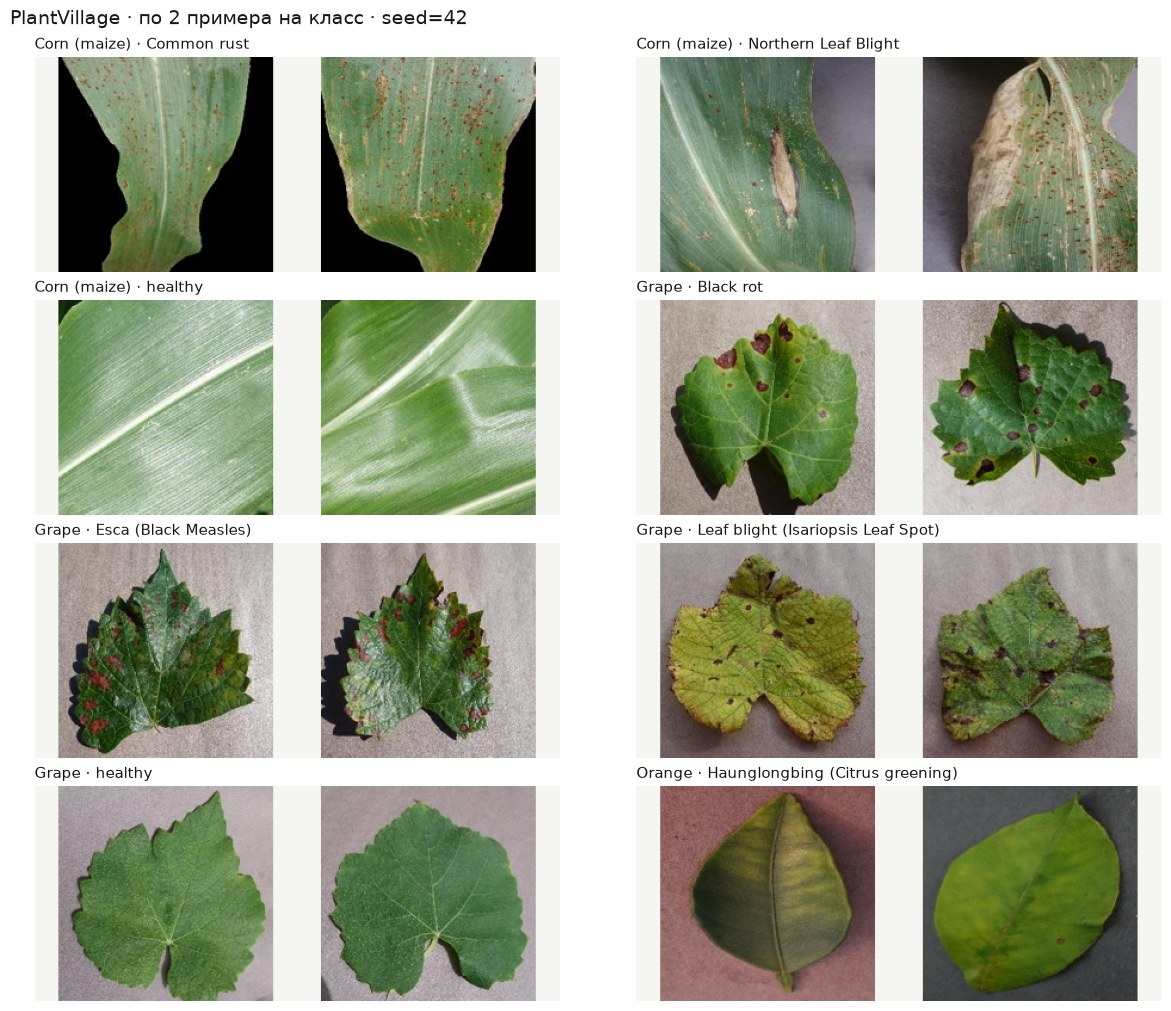

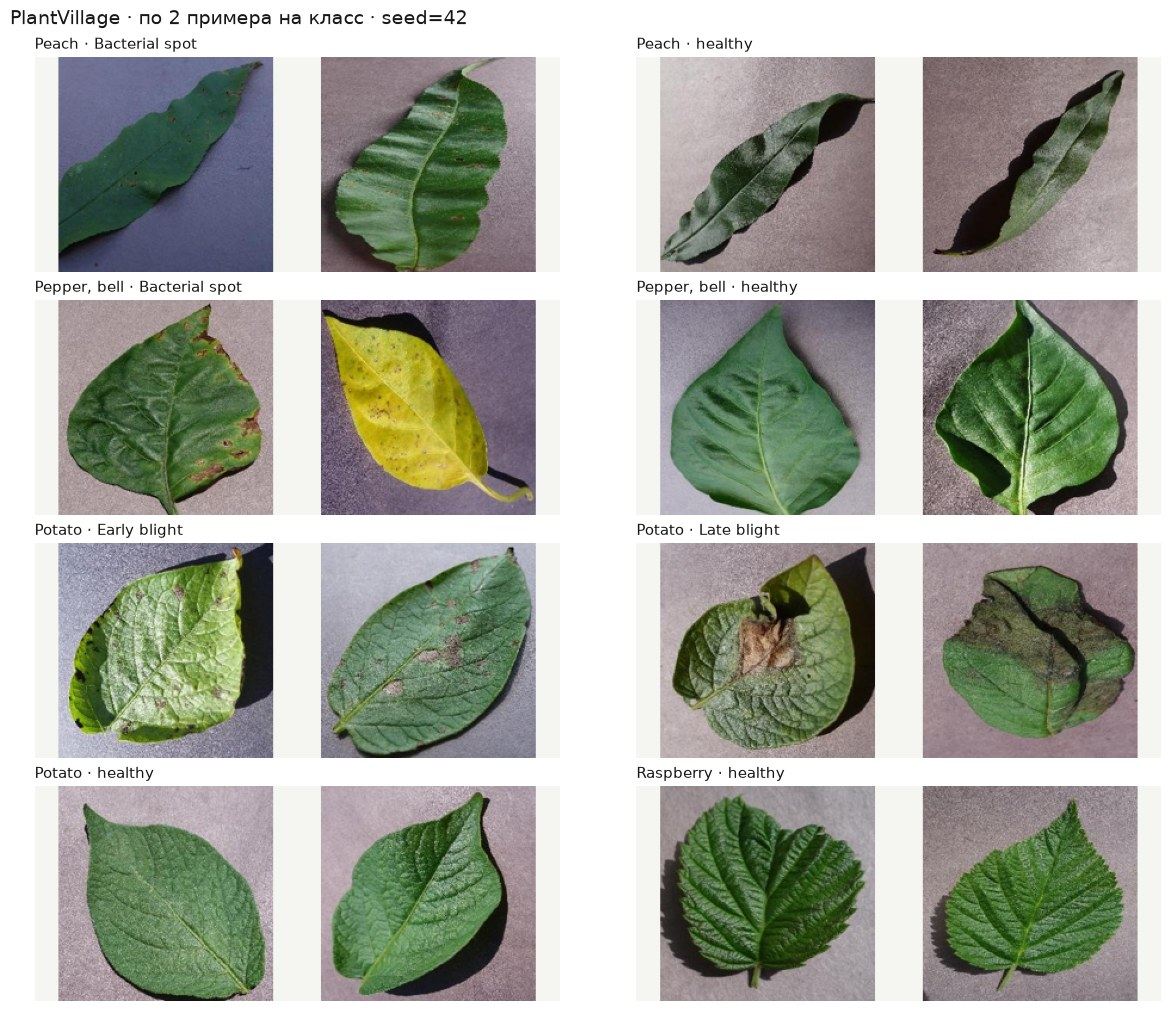

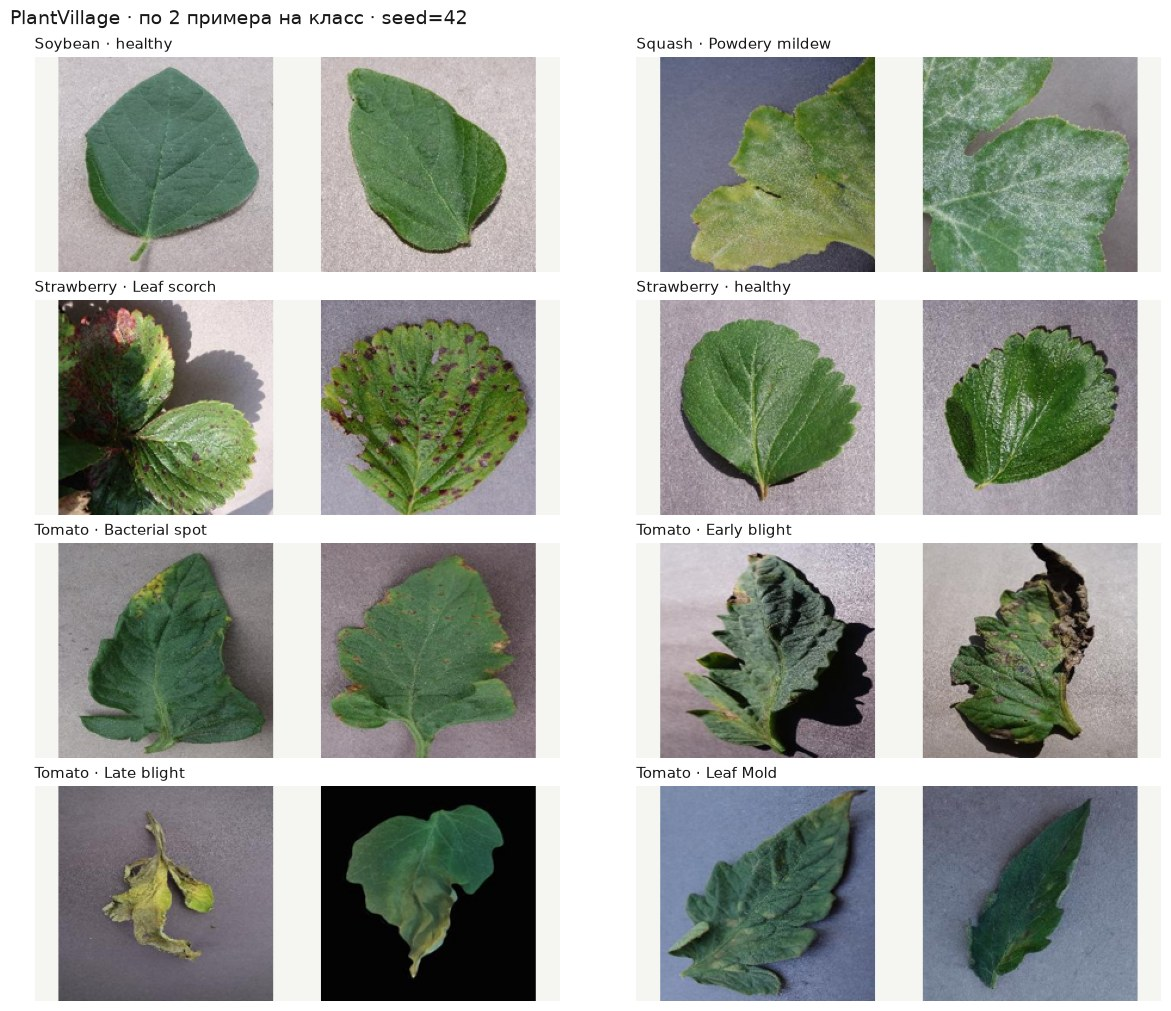

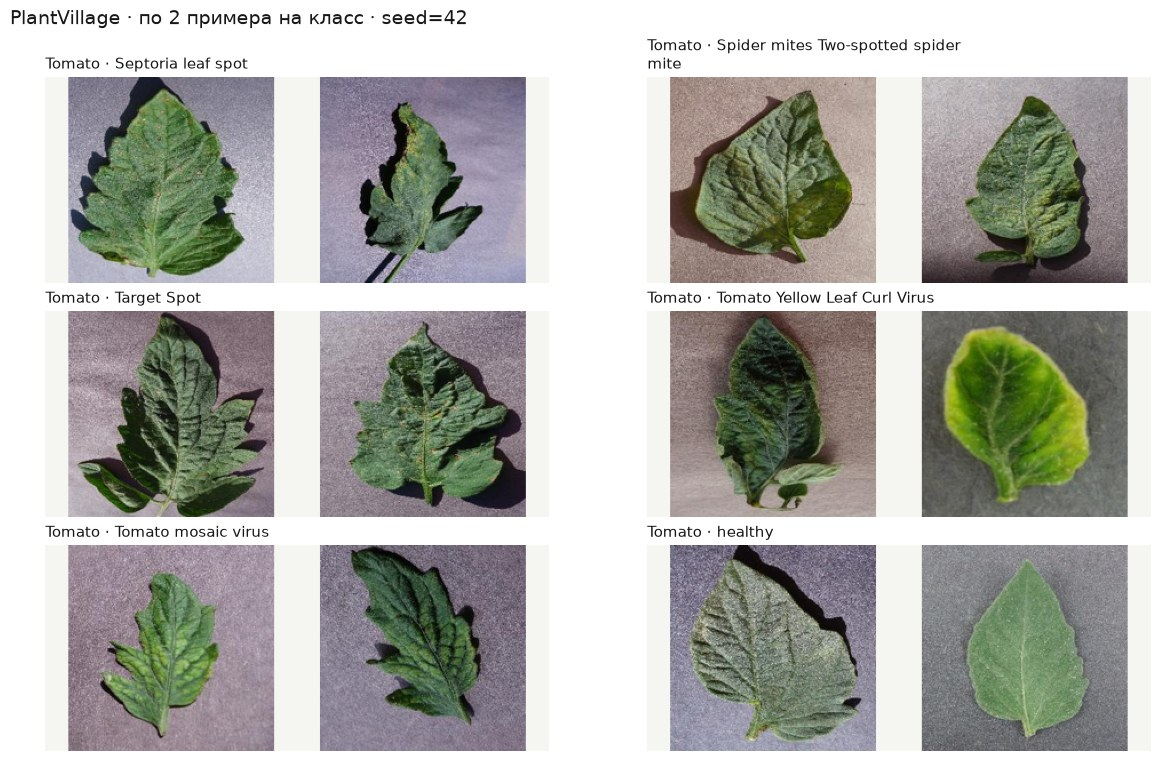

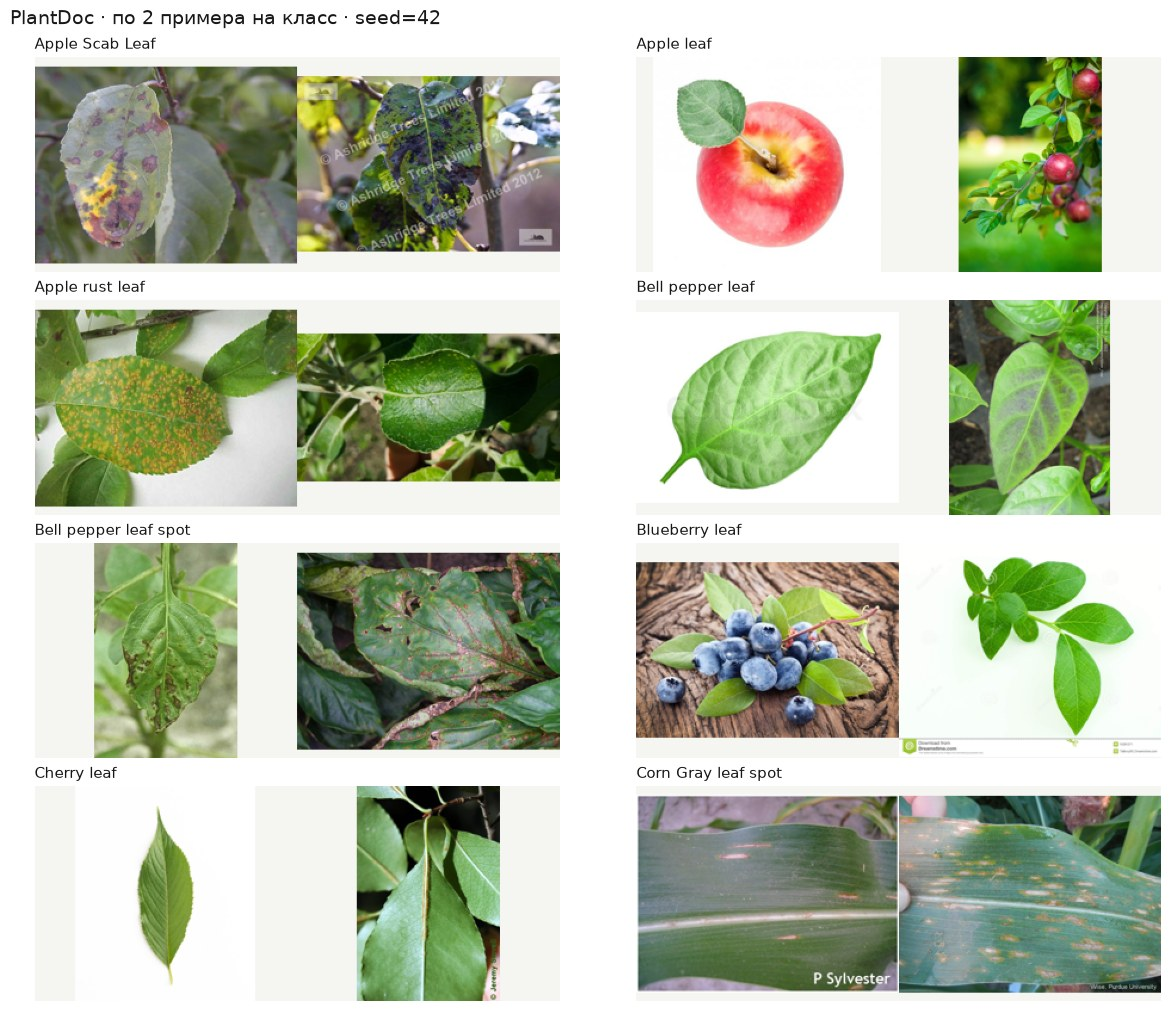

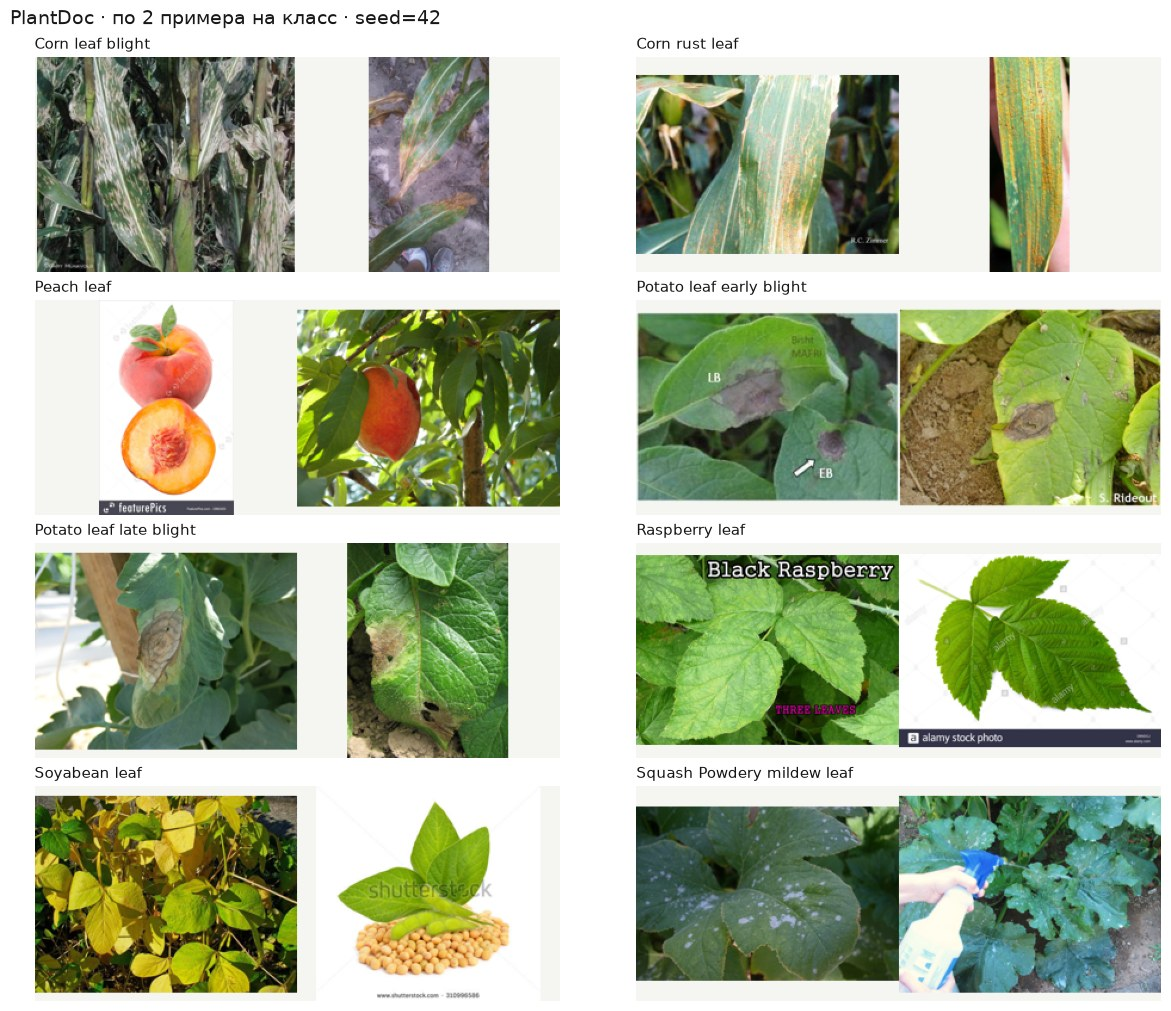

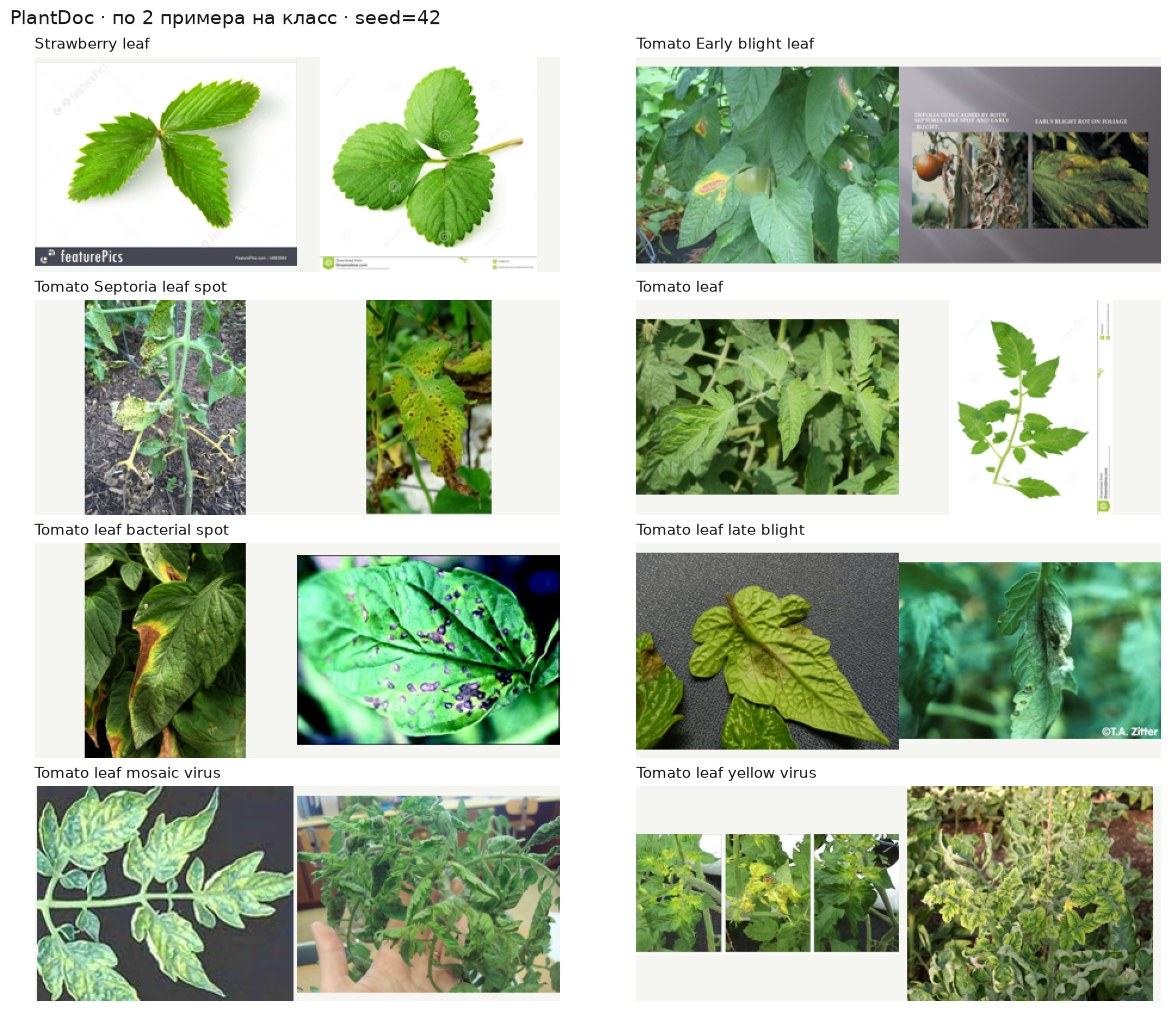

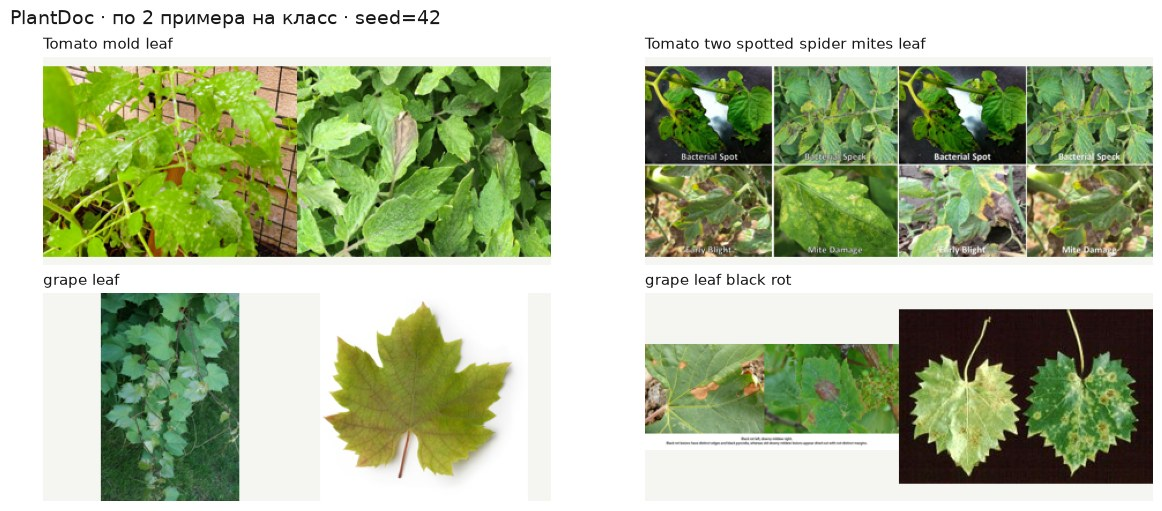

In [7]:
plots.class_galleries(df)

В PlantVillage обычно виден один лист на простом фоне. В PlantDoc встречаются ветви, плоды, несколько листьев, надписи, коллажи и водяные знаки. На таких фотографиях модели сложнее понять, к какому объекту относится метка. Она также может запомнить фон или оформление вместо признаков болезни.

<a id="duplicates"></a>
## 4. Дубликаты и почти-дубликаты

Точные копии определяем по хешам файлов и RGB-пикселей с учетом размера изображения. Для поиска похожих фото используем 64-битный pHash и BK-tree. Расстояние Хэмминга показывает, сколько битов различается у двух хешей; рассматриваем пары с расстоянием до 6.

Для каждой пары также считаем среднее абсолютное отличие RGB после уменьшения изображений до 64×64. Значения каналов приводим к диапазону от 0 до 1. Почти-дубликатами считаем пары, которые проходят оба порога.

Пороги подбираем кодом по авторским `leaf_id` PlantVillage. Одинаковый идентификатор означает один лист. Он помогает проверить, не объединяет ли правило разные листья, но сам по себе не доказывает, что два снимка являются копиями.

По `leaf_id` и seed=42 делим листья примерно 70/30 на подбор и проверку. Пару используем, только если оба листа попали в одну часть. Это отдельное техническое разбиение: один лист не может участвовать одновременно в подборе и проверке порогов.

Перебираем Хэмминг 0/2/4/6 и RGB от 0.005 до 0.15 с шагом 0.005. На части для подбора выбираем вариант, который находит больше пар одного листа и не объединяет разные листья. При равенстве выбираем меньший порог Хэмминга, затем RGB.

In [8]:
from duplicate_audit import calibrate

calibration, calibration_grid = calibrate(df, pairs)
# Показываем лучшие варианты без ошибок по авторским leaf_id на части для подбора.
display(calibration_grid.query('fp == 0 and tp > 0')
        .sort_values(['tp', 'hamming_max', 'rgb_mae_max'], ascending=[False, True, True])
        .head(8).rename(columns={'hamming_max': 'Хэмминг', 'rgb_mae_max': 'RGB',
                                'tp': 'Пары одного листа', 'fp': 'Разные листья',
                                'fn': 'Не отобранные пары одного листа', 'tn': 'Отсеянные разные листья'}))
display(pd.DataFrame({part: calibration[part] for part in ['fit', 'holdout']}).T
        .rename(index={'fit': 'Подбор', 'holdout': 'Проверка'},
                columns={'tp': 'Пары одного листа', 'fp': 'Разные листья',
                         'fn': 'Не отобранные пары одного листа', 'tn': 'Отсеянные разные листья'}))
assert calibration['holdout']['fp'] == 0
selected_hamming = calibration['hamming_max']
selected_rgb = calibration['rgb_mae_max']
display(Markdown(f'Код выбрал пороги: **Хэмминг ≤ {selected_hamming}, RGB ≤ {selected_rgb:.3f}**. '
                 f'Им соответствуют **{calibration["candidate_count"]} пар** без точных копий.'))

,Хэмминг,RGB,Пары одного листа,Разные листья,Не отобранные пары одного листа,Отсеянные разные листья
96,6,0.035,17,0,429,4485
40,2,0.055,12,0,434,4485
67,4,0.040,12,0,434,4485
95,6,0.030,10,0,436,4485
39,2,0.050,9,0,437,4485
38,2,0.045,7,0,439,4485
66,4,0.035,7,0,439,4485
65,4,0.030,5,0,441,4485


,Пары одного листа,Разные листья,Не отобранные пары одного листа,Отсеянные разные листья
Подбор,17,0,429,4485
Проверка,10,0,162,935


Код выбрал пороги: **Хэмминг ≤ 6, RGB ≤ 0.035**. Им соответствуют **97 пар** без точных копий.

Получились пороги **Хэмминг ≤ 6 и RGB ≤ 0.035**. При подборе они выделили 17 пар с одинаковым `leaf_id`, на отдельной проверочной части 10. Пар с разными `leaf_id` в обоих случаях было 0. Таблица перебора сохранена в `reports/duplicate_calibration_grid.csv`.

Ниже показаны две пары, которые код считает почти-дубликатами: обе проходят пороги Хэмминга и RGB. Все расчеты по найденным парам сохранены в `reports/duplicate_rule_results.csv`.

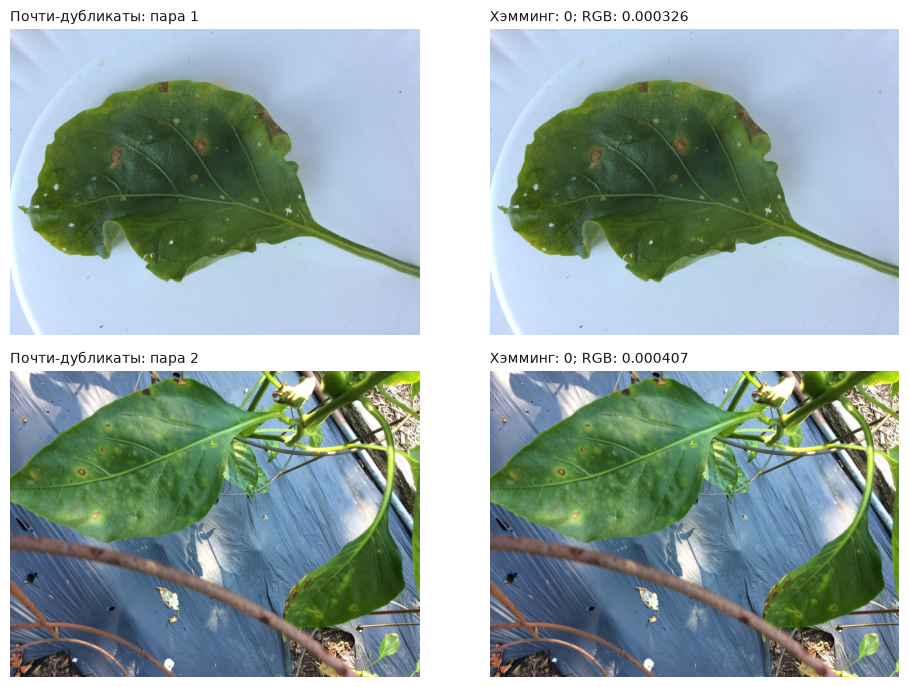

In [9]:
from PIL import Image, ImageOps

image_paths = valid.set_index('image_id')['path']
examples = pairs[pairs.near_duplicate].sort_values(
    ['distance', 'rgb_mae', 'left_id', 'right_id']).head(2)
assert len(examples) == 2
assert examples.distance.le(selected_hamming).all() and examples.rgb_mae.le(selected_rgb).all()
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, (_, pair) in enumerate(examples.iterrows()):
    for col, key in enumerate(['left_id', 'right_id']):
        with Image.open(ROOT / image_paths.loc[pair[key]]) as image:
            axes[row, col].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row, col].axis('off')
    axes[row, 0].set_title(f'Почти-дубликаты: пара {row + 1}', loc='left', fontsize=10)
    axes[row, 1].set_title(f'Хэмминг: {pair.distance}; RGB: {pair.rgb_mae:.6f}', loc='left', fontsize=10)
fig.tight_layout()
fig.savefig(ROOT / 'reports/figures/duplicate_threshold_examples.png', dpi=150)
plt.show()

1. **Находим точные копии и почти-дубликаты.** Используем совпадение SHA-256 файлов или пикселей либо одновременное выполнение порогов pHash и RGB.
2. **Объединяем найденные пары в группы.** Если A совпадает с B, а B с C, все три файла входят в одну группу.
3. **В группе оставляем один файл.** Приоритет: PlantDoc test, PlantDoc train, PlantVillage. Внутри каждого набора выбираем по пути файла в алфавитном порядке. Если у файлов разные метки классов, исключаем всю группу.
4. **Учитываем группы при разбиении.** Найденные повторы и снимки с одинаковым `leaf_id` остаются в одной части выборки.

,Hamming radius,candidate_pairs
0,0,78
1,2,182
2,4,1534
3,6,10604


pairs
exact_pixels remove_candidate       
False        False             10469
             True                 97
True         True                 38

Лишние побайтовые копии внутри источников: {'plantdoc': 12, 'plantvillage': 21}
Пар между датасетами (pHash ≤6): 16
Из них проходят полное правило удаления: 0


images
dataset      exclusion_reason                
plantdoc     duplicate_label_conflict      60
             duplicate_removed             33
plantvillage duplicate_removed             69

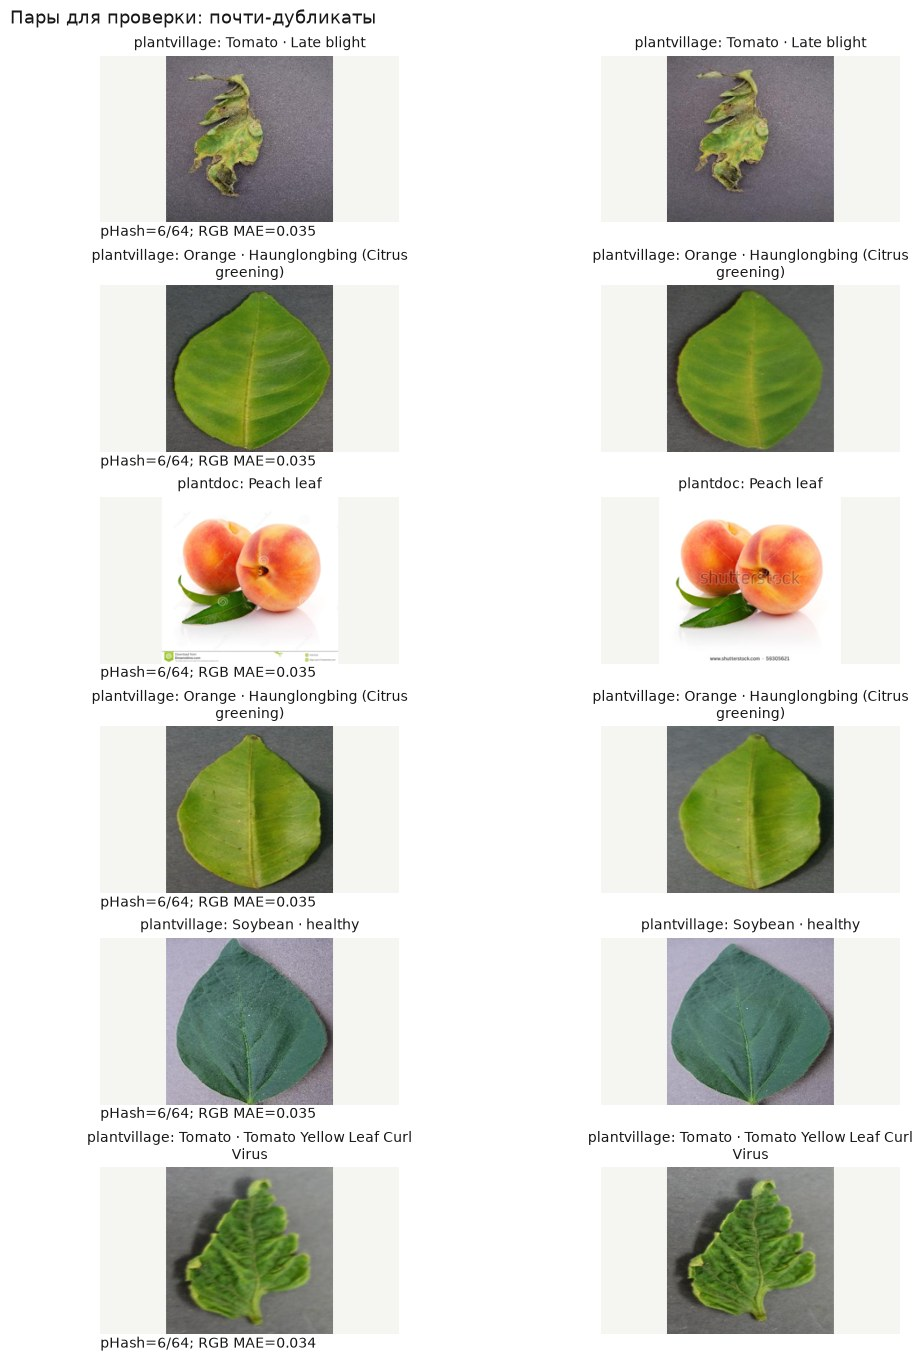

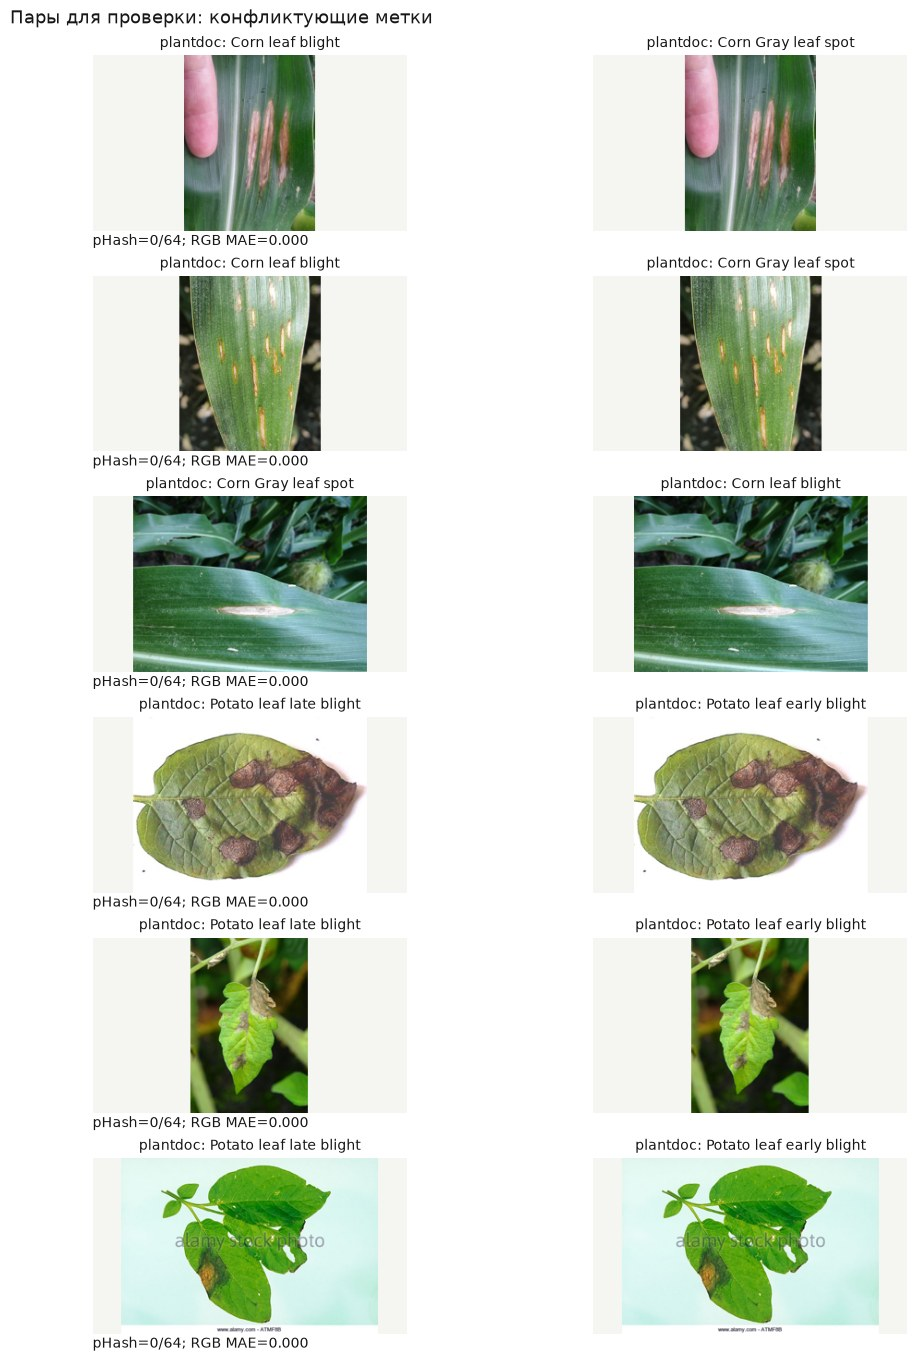

In [10]:
sensitivity = pd.DataFrame({'Hamming radius':[0,2,4,6],
                            'candidate_pairs':[int(pairs.distance.le(r).sum()) for r in [0,2,4,6]]})
display(sensitivity)
display(pairs.groupby(['exact_pixels','remove_candidate']).size().rename('pairs').to_frame())
byte_counts = valid.groupby(['dataset','sha256']).size().groupby(level=0).apply(lambda s:int((s-1).clip(lower=0).sum()))
print('Лишние побайтовые копии внутри источников:', byte_counts.to_dict())
print('Пар между датасетами (pHash ≤6):', int(pairs.cross_dataset.sum()))
print('Из них проходят полное правило удаления:', int((pairs.cross_dataset & pairs.remove_candidate).sum()))
removals = df[df.exclusion_reason.ne('')].groupby(['dataset','exclusion_reason']).size().rename('images')
display(removals.to_frame())
df[df.exclusion_reason.ne('')][['image_id','path','label','exclusion_reason','duplicate_of','duplicate_group']].to_csv(
    ROOT / 'reports/exclusions.csv', index=False)
sensitivity.to_csv(ROOT / 'reports/phash_sensitivity.csv', index=False)
plots.pair_gallery(df, pairs, 'near')
plots.pair_gallery(df, pairs, 'conflict')

По автоматическому правилу исключили 69 повторных фото PlantVillage и 33 PlantDoc. Еще в PlantDoc исключили 60 фото из групп с противоречивыми метками. Например, снимки одной группы встретились в классах `Corn leaf blight` и `Corn Gray leaf spot`.

Всего исключили 162 изображения. Причины записаны в `reports/exclusions.csv` и `splits/manifest.csv`. Исходные файлы сохранены.

<a id="conditions"></a>
## 5. Фон, освещение и цвет

Сравним несколько характеристик изображений:

- яркость: среднее `0.299R + 0.587G + 0.114B`;
- насыщенность: среднюю S в HSV;
- резкость: дисперсию лапласиана яркости после уменьшения до 128×128;
- края изображения: внешние 13 пикселей с каждой стороны на размере 128×128.

По краям грубо оцениваем фон. Туда может попасть и лист, поэтому эта оценка не заменяет маску листа. Яркость здесь описывает само изображение,  не освещенность при съемке.

brightness         saturation         contrast         sharpness  \
                 median    mean     median    mean   median    mean    median   
dataset                                                                         
plantdoc         0.4763  0.5105     0.3951  0.4097   0.1901  0.1933    0.0207   
plantvillage     0.4701  0.4734     0.2531  0.2638   0.1486  0.1487    0.0135   

                     border_brightness         border_std          
                mean            median    mean     median    mean  
dataset                                                            
plantdoc      0.0259            0.4600  0.5111     0.1757  0.1766  
plantvillage  0.0149            0.5235  0.5283     0.1143  0.1220

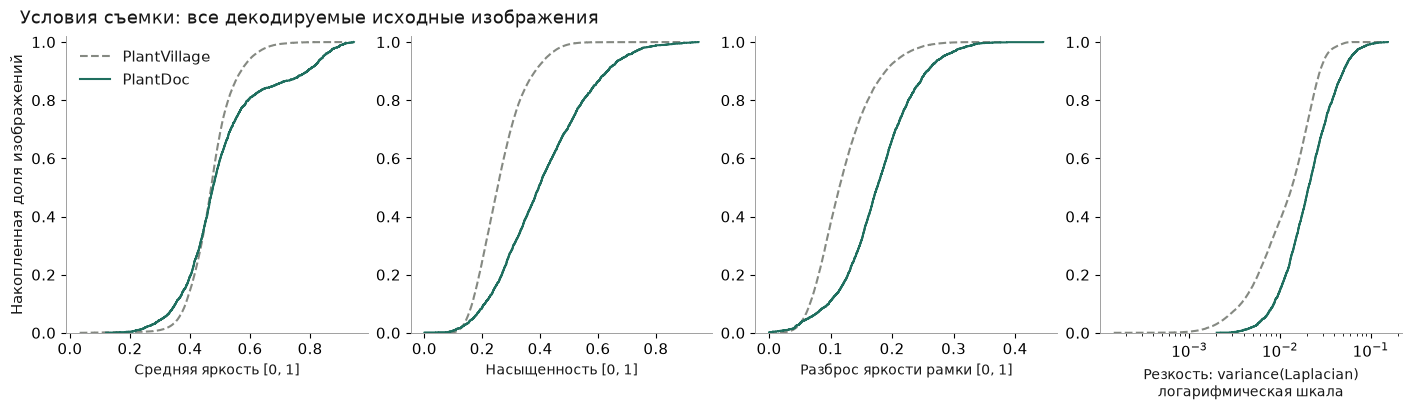

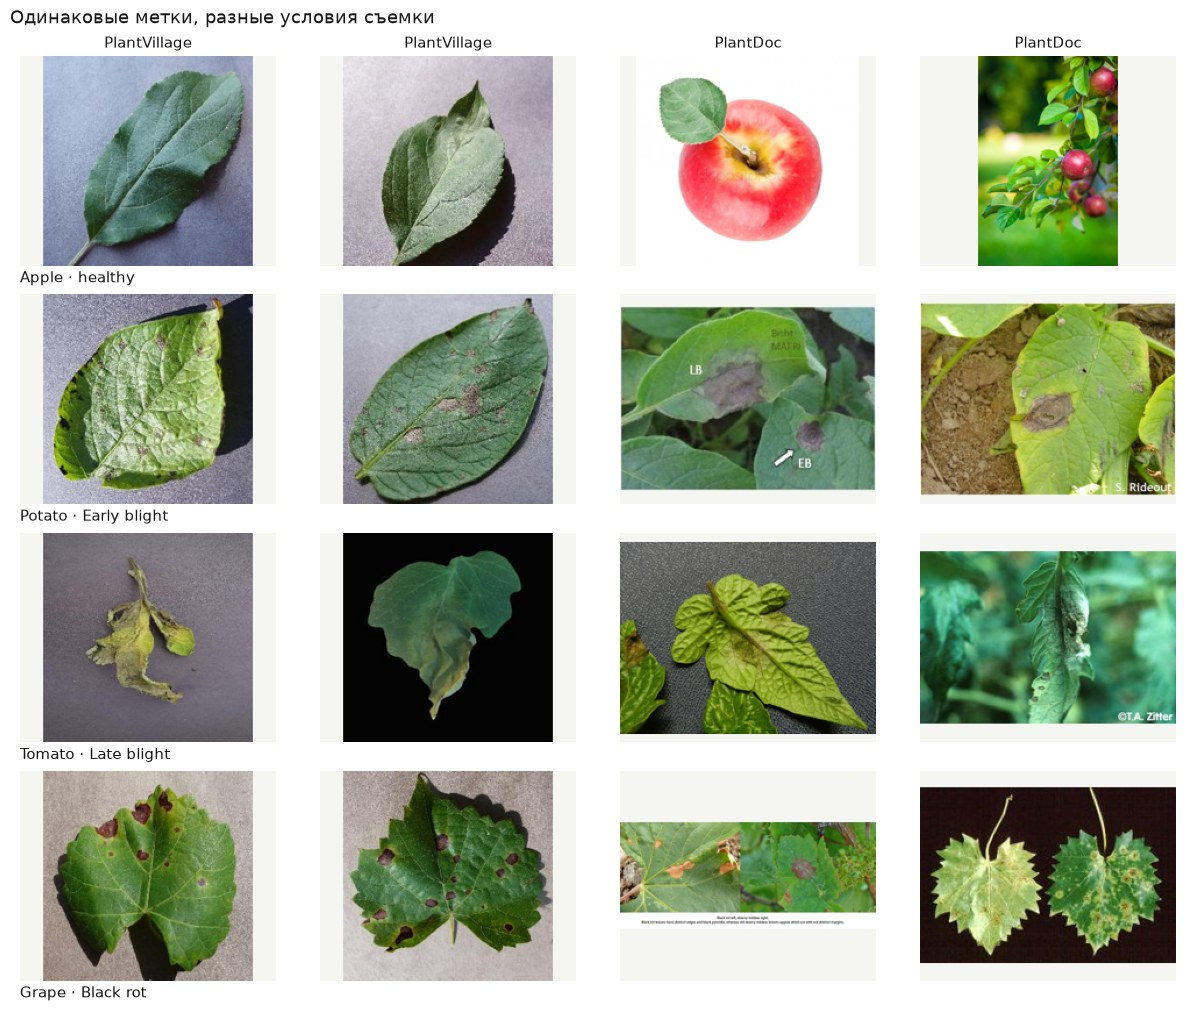

In [11]:
metrics = ['brightness','saturation','contrast','sharpness','border_brightness','border_std']
display(valid.groupby('dataset')[metrics].agg(['median','mean']).round(4))
plots.shooting_conditions(valid)
plots.paired_domains(df)

Даже при одинаковой метке сцены сильно отличаются. В PlantVillage это отдельные листья, а в PlantDoc также видны яблоки, ветви, земля и подписи. Разница не сводится к освещению.

На общие статистики влияет и состав классов. Чтобы уменьшить это влияние, ниже берем только общие классы: сначала считаем среднее внутри каждого класса и датасета, затем усредняем классы с одинаковым весом.

,brightness,saturation,contrast,sharpness,border_brightness,border_std
dataset,,,,,,
plantdoc,0.5232,0.4082,0.1943,0.0251,0.5278,0.1741
plantvillage,0.4799,0.2444,0.1557,0.0168,0.5377,0.1274


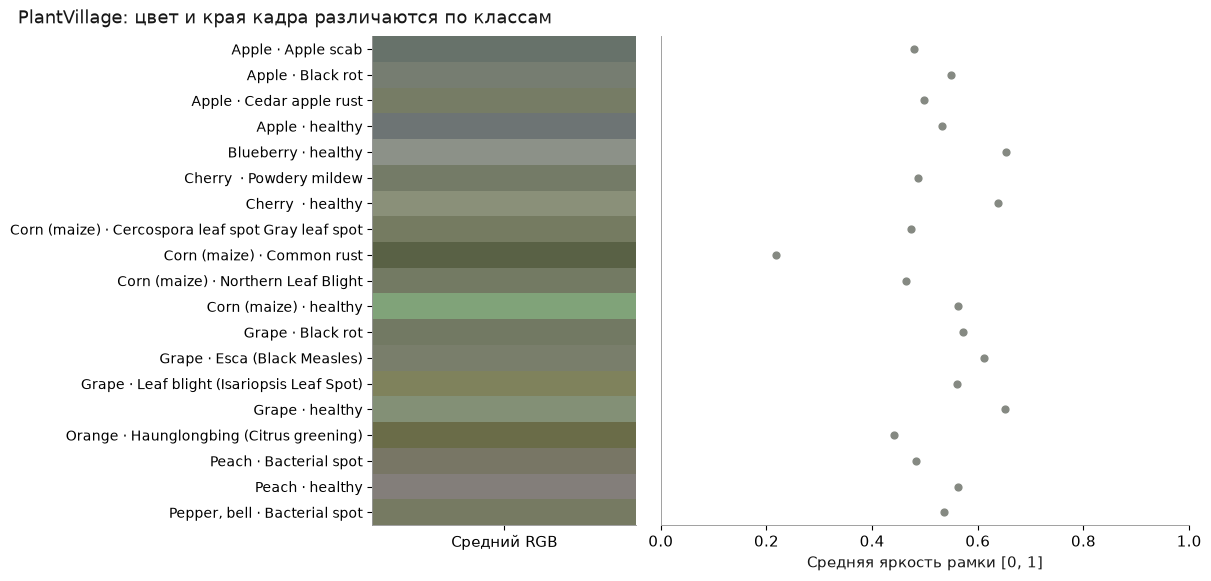

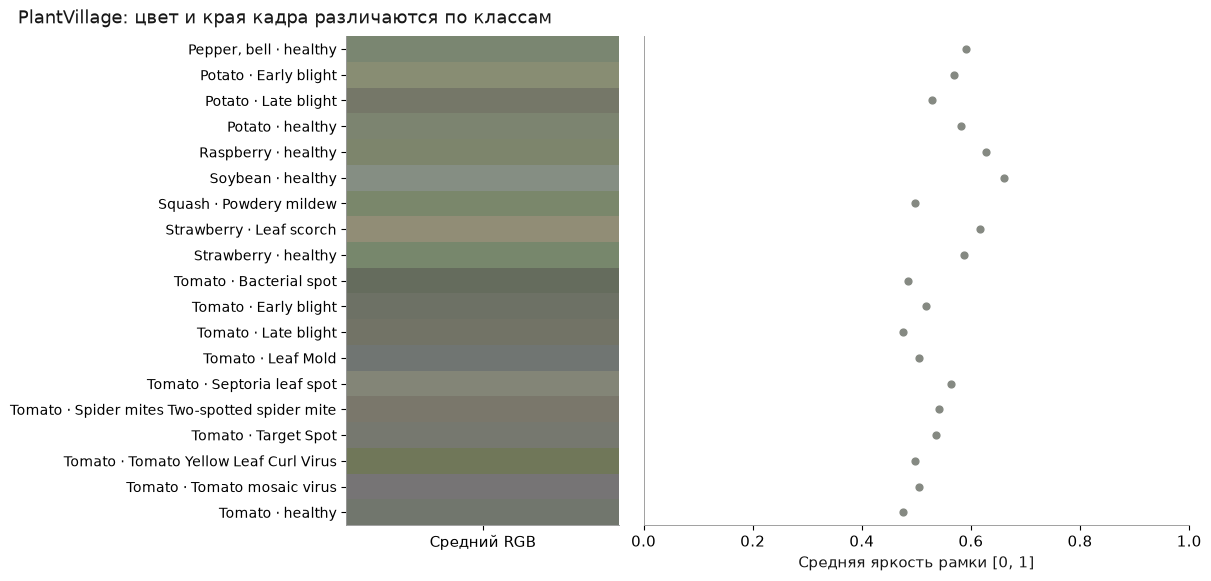

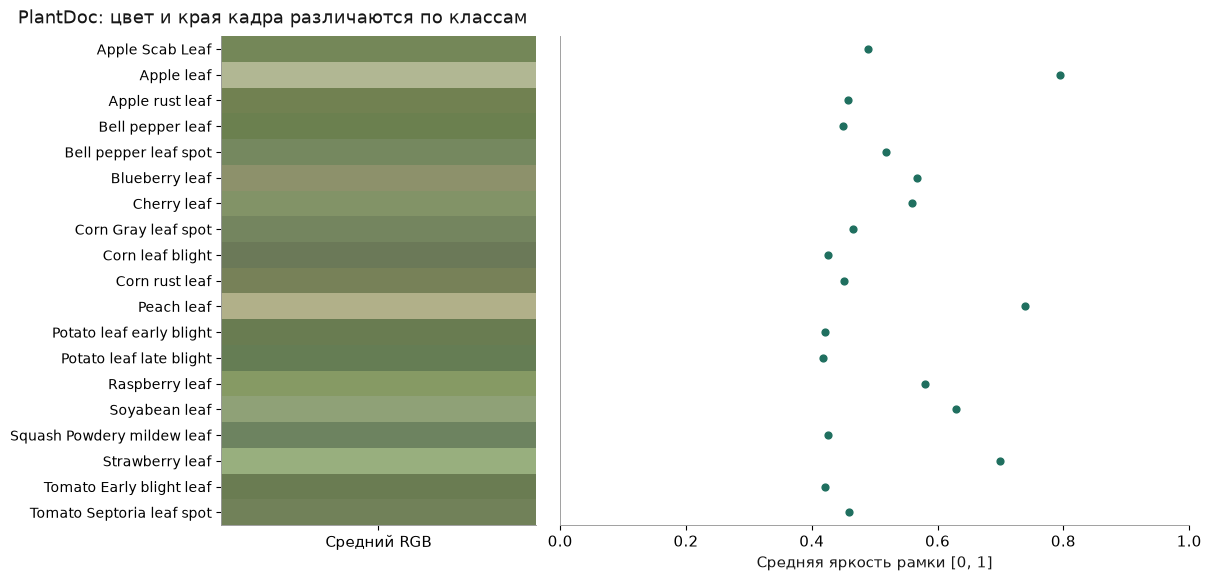

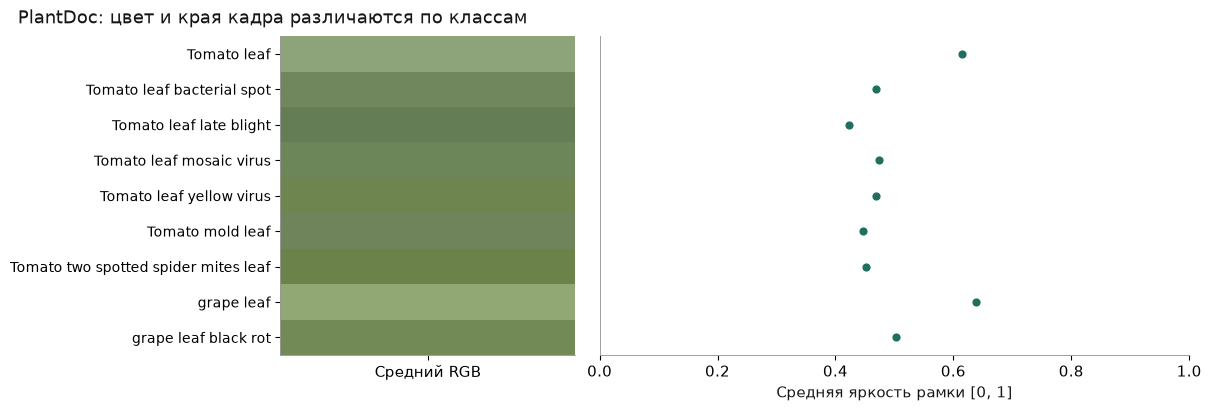

,brightness,border_brightness,mean_g
plantdoc,0.229,0.243,0.219
plantvillage,0.417,0.568,0.431


In [12]:
matched = clean[clean.common_primary].groupby(['dataset','canonical_label'])[metrics].mean()
display(matched.groupby('dataset').mean().round(4))
matched.to_csv(ROOT / 'reports/conditions_by_common_class.csv')
plots.color_by_class(valid)
# Fraction of between-class variance in a feature, descriptive eta squared.
def eta_squared(group, feature):
    x = group[feature].astype(float)
    denominator = ((x-x.mean())**2).sum()
    if denominator == 0:
        return np.nan
    stats = group.groupby('label')[feature].agg(['mean','size'])
    return float((stats['size']*(stats['mean']-x.mean())**2).sum()/denominator)
eta = pd.DataFrame({ds:{feature:eta_squared(g,feature) for feature in ['brightness','border_brightness','mean_g']}
                    for ds,g in valid.groupby('dataset')}).T
display(eta.round(3))

Медианная яркость близка: 0.470 у PlantVillage и 0.476 у PlantDoc. При этом медианная насыщенность составляет 0.253 и 0.395, а разброс яркости краев 0.114 и 0.176. Разница насыщенности сохраняется и при одинаковом весе общих классов: средние равны 0.244 и 0.408. Значит, одного изменения яркости для сближения датасетов вряд ли хватит.

Цвет и яркость краев различаются между классами. Это возможная подсказка для модели: она может запоминать фон вместо болезни. Пока это гипотеза, ведь в измерения попадает и сам лист. Позже проверим ее с помощью обрезки, замены фона и Grad-CAM с маской листа.

<a id="augmentations"></a>
## 6. Проверка аугментаций

Посмотрим, как преобразования меняют снимки из train и field_dev. Отражения, небольшие повороты и умеренные изменения яркости выглядят правдоподобно, пока симптомы остаются видны. С обрезкой и изменением оттенка нужно осторожнее: можно убрать пораженный участок или изменить характерный цвет болезни.

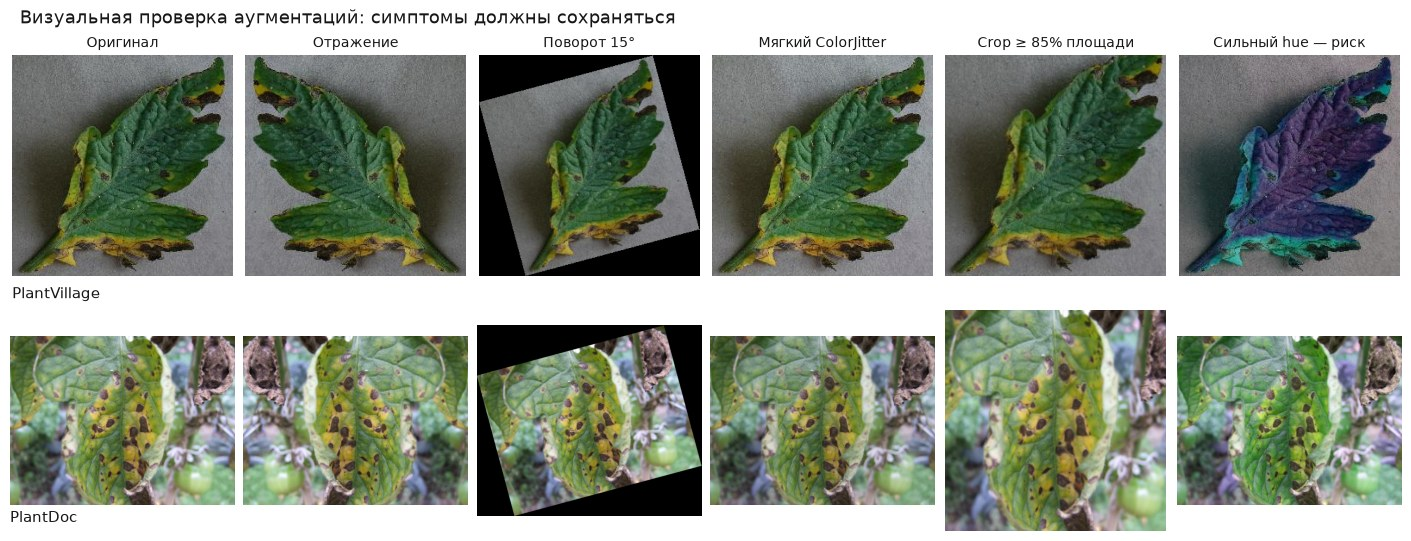

In [13]:
plots.augmentation_gallery(df)

| Преобразование | Что попробуем при обучении | На что обратить внимание |
|---|---|---|
| Отражение по горизонтали, p=0.5 | Включить в первый набор аугментаций | На снимках бывают надписи |
| Поворот до ±15° | Начать с небольших углов | Заполнять края отражением, чтобы не создавать черные углы |
| Яркость/контраст ±15%, насыщенность ±10%, оттенок ±0.02 | Начать с этих мягких настроек | Цвет и контраст симптомов должны сохраняться |
| RandomResizedCrop, площадь 0.85-1.0 | Проверить на примерах перед обучением | Обрезка может убрать больной участок |
| Сильное изменение оттенка и большая обрезка | Пока не использовать | На примерах теряется цвет или видимость симптомов |
| RandAugment, MixUp/CutMix, замена фона | Сравнить отдельно на чекпоинте 5 | Проверять пользу на validation |

Здесь проверили только внешний вид преобразований. Помогают ли они модели, станет понятно после обучения. Случайные аугментации будем применять к train; для val и test оставим фиксированную обработку. В примере поворота холст расширен, поэтому видны пустые углы.

<a id="embeddings"></a>
## 7. Признаки ResNet18 и t-SNE

Возьмем ResNet18 с весами ImageNet-1K V1 и уберем последний слой. Для каждого снимка получим 512 чисел, описывающих его признаки. Сеть не дообучаем.

Перед подачей в сеть уменьшаем короткую сторону до 256, вырезаем центр 224×224 и применяем нормализацию ImageNet. У PlantDoc такая обрезка иногда может убрать часть объекта. (Это стандартная обработка для выбранных предобученных весов ResNet18. Мы берем ее готовой через ResNet18_Weights.IMAGENET1K_V1.transforms())

Для отдельных карт выбираем до 60 разных групп снимков на класс из PlantVillage train и PlantDoc field_dev. Для общей карты берем до 40 на класс из каждого датасета, с одинаковым числом снимков в каждой паре.

Признаки нормируем по L2, сокращаем до 50 компонент с PCA (50 взяли как типичное стартовое значение из рекомендации scikit-learn), затем строим t-SNE: `perplexity=30`, 1000 итераций, `seed=42`. Точки и параметры сохраняем. На картах классов выделяем по одному классу, чтобы не смешивать десятки цветов на одном графике.

Дополнительно считаем silhouette по исходным 512 признакам ResNet18: он сравнивает близость снимков внутри своего класса и к ближайшему другому классу. Это численная оценка разделения классов в дополнение к графикам t-SNE. На общей выборке также считаем silhouette по источнику снимков, чтобы оценить разделение PlantVillage и PlantDoc.

,n,classes,class_silhouette_cosine_512d,domain_silhouette_cosine_512d
pv,2164,38,0.0829,—
pd,1566,28,-0.0931,—
joint,1812,23,0.0017,0.2203


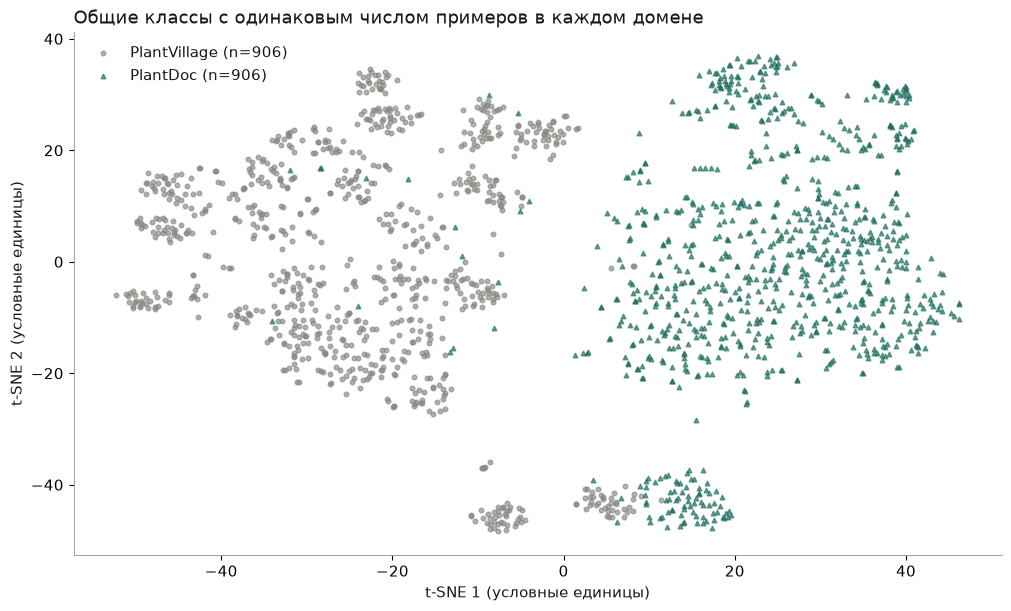

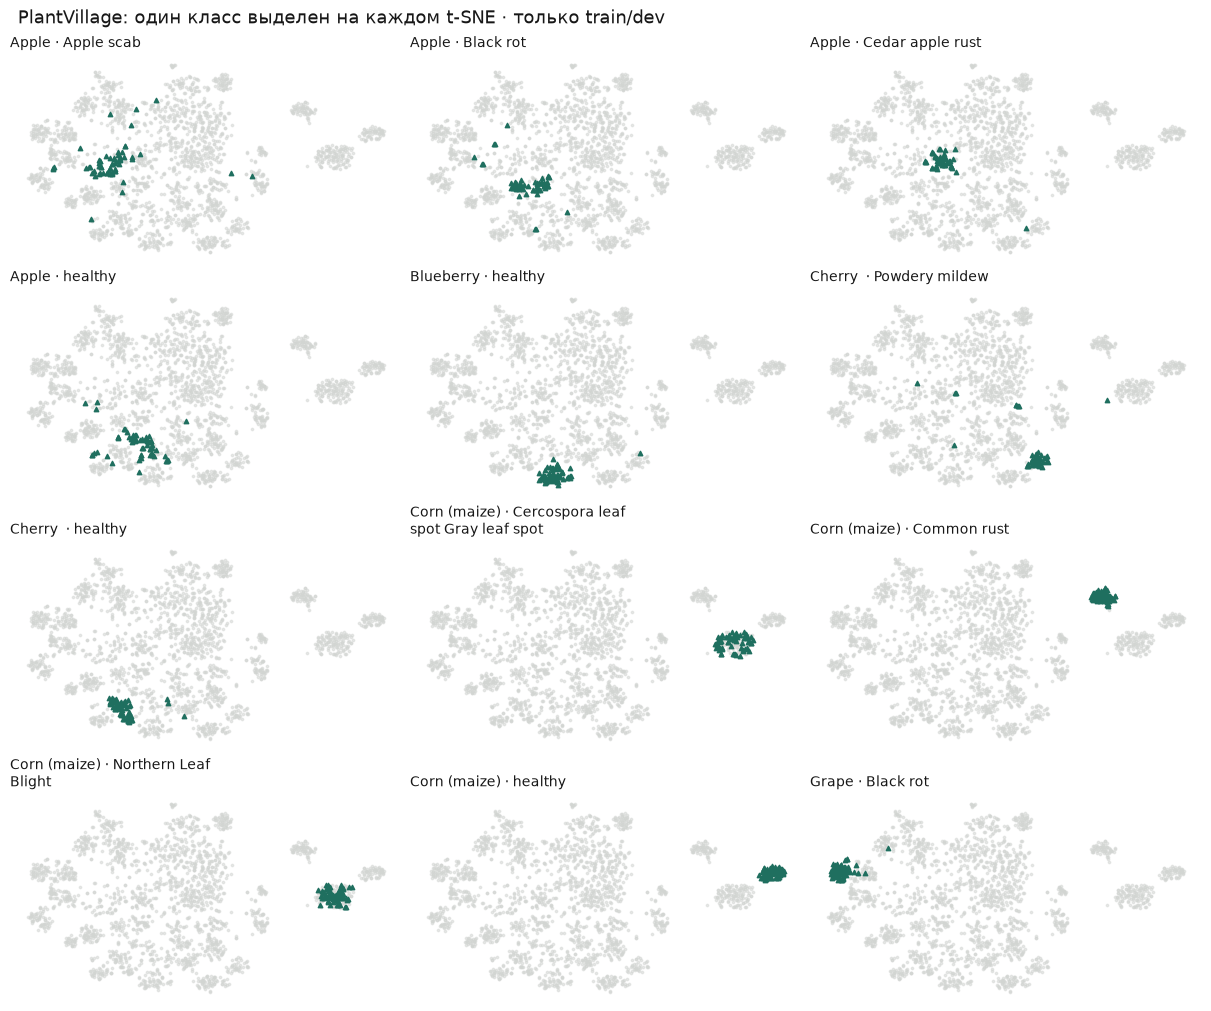

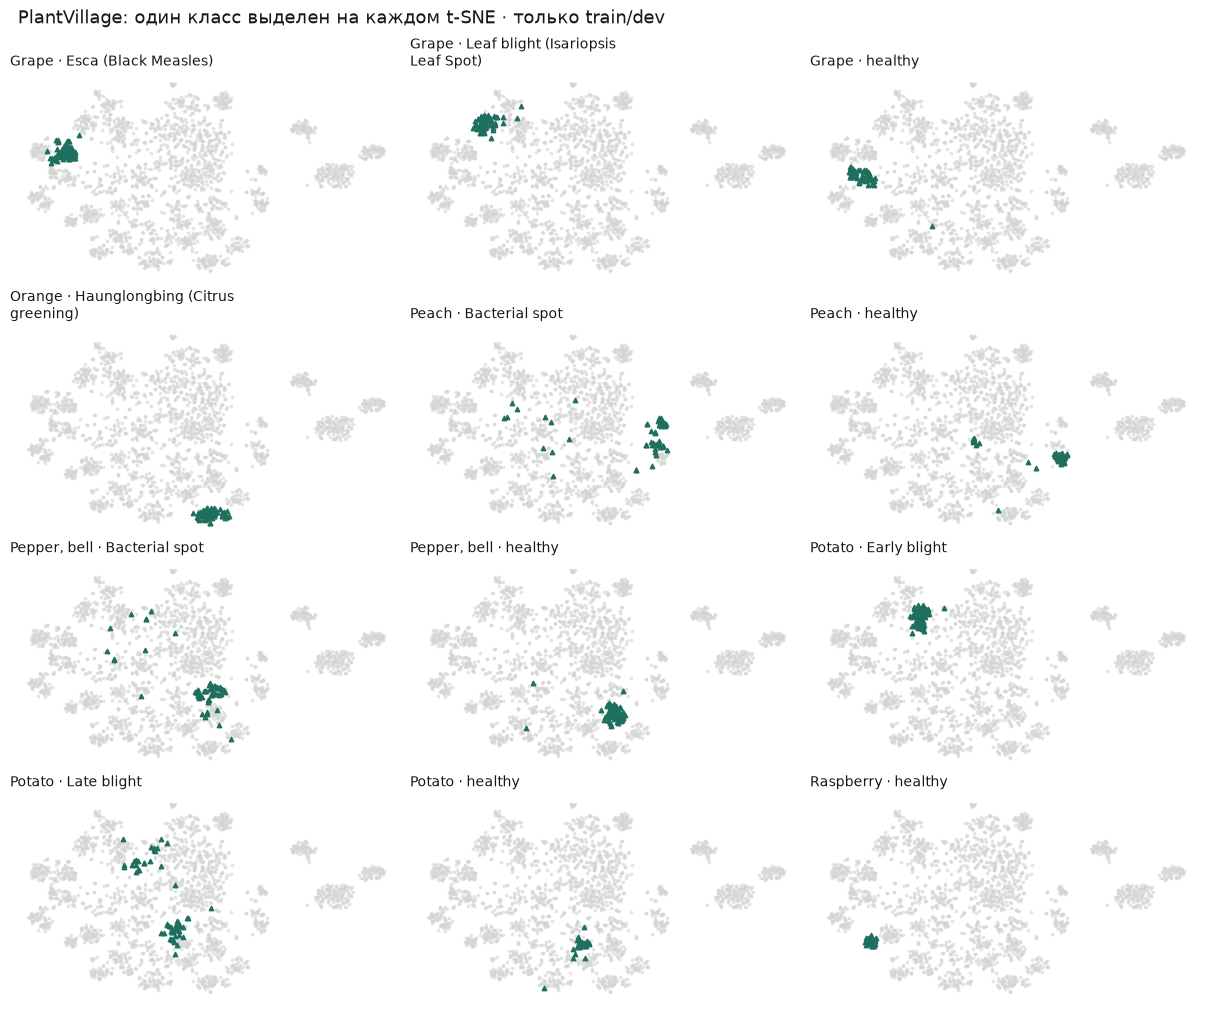

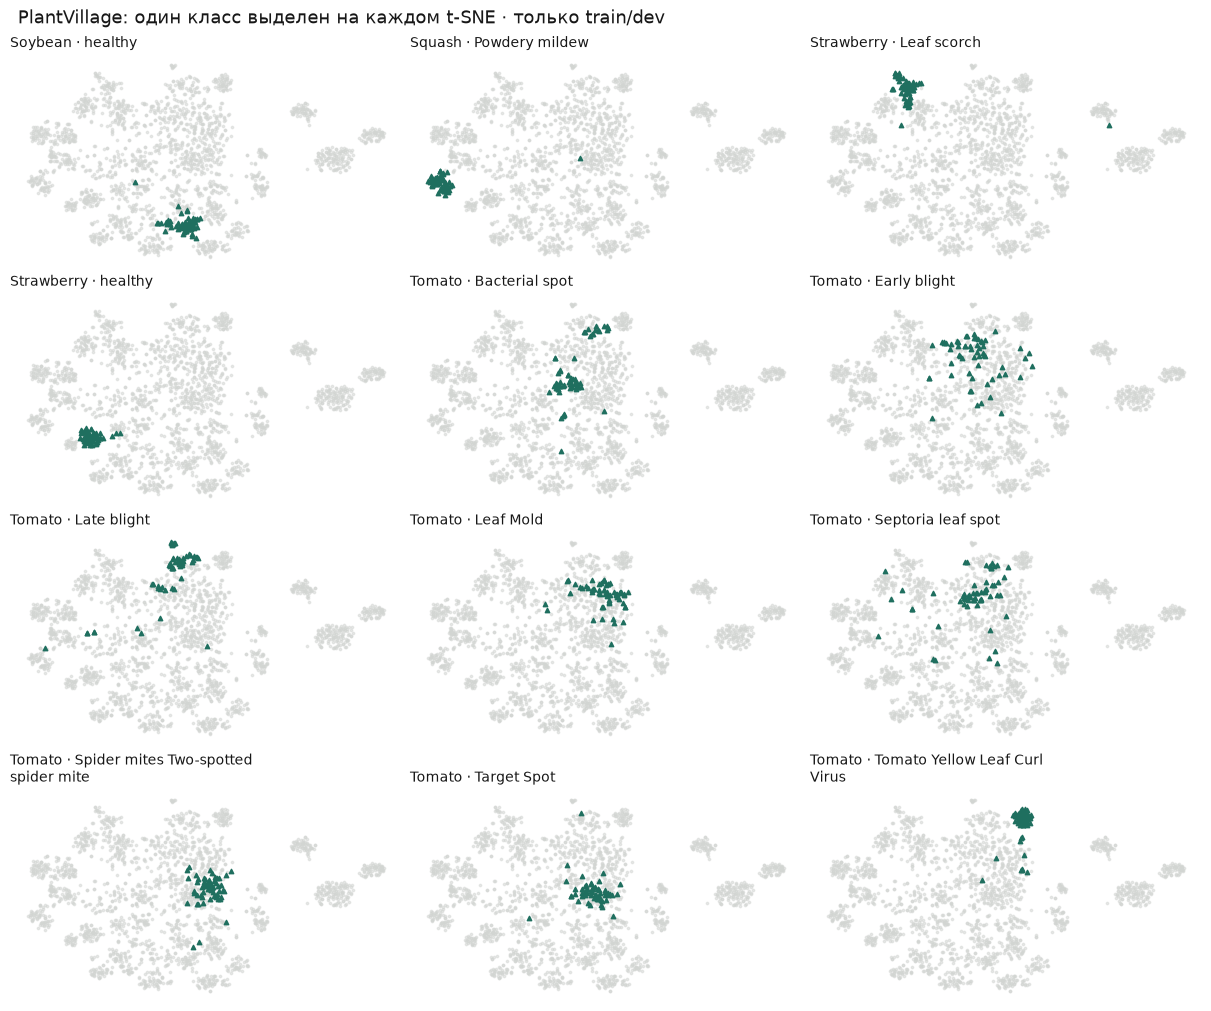

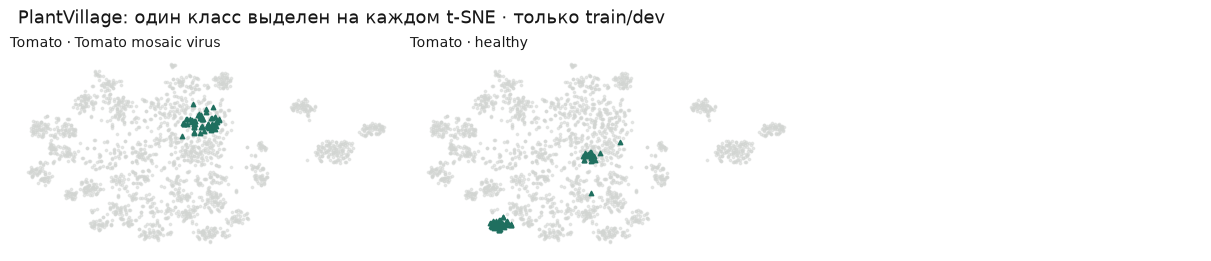

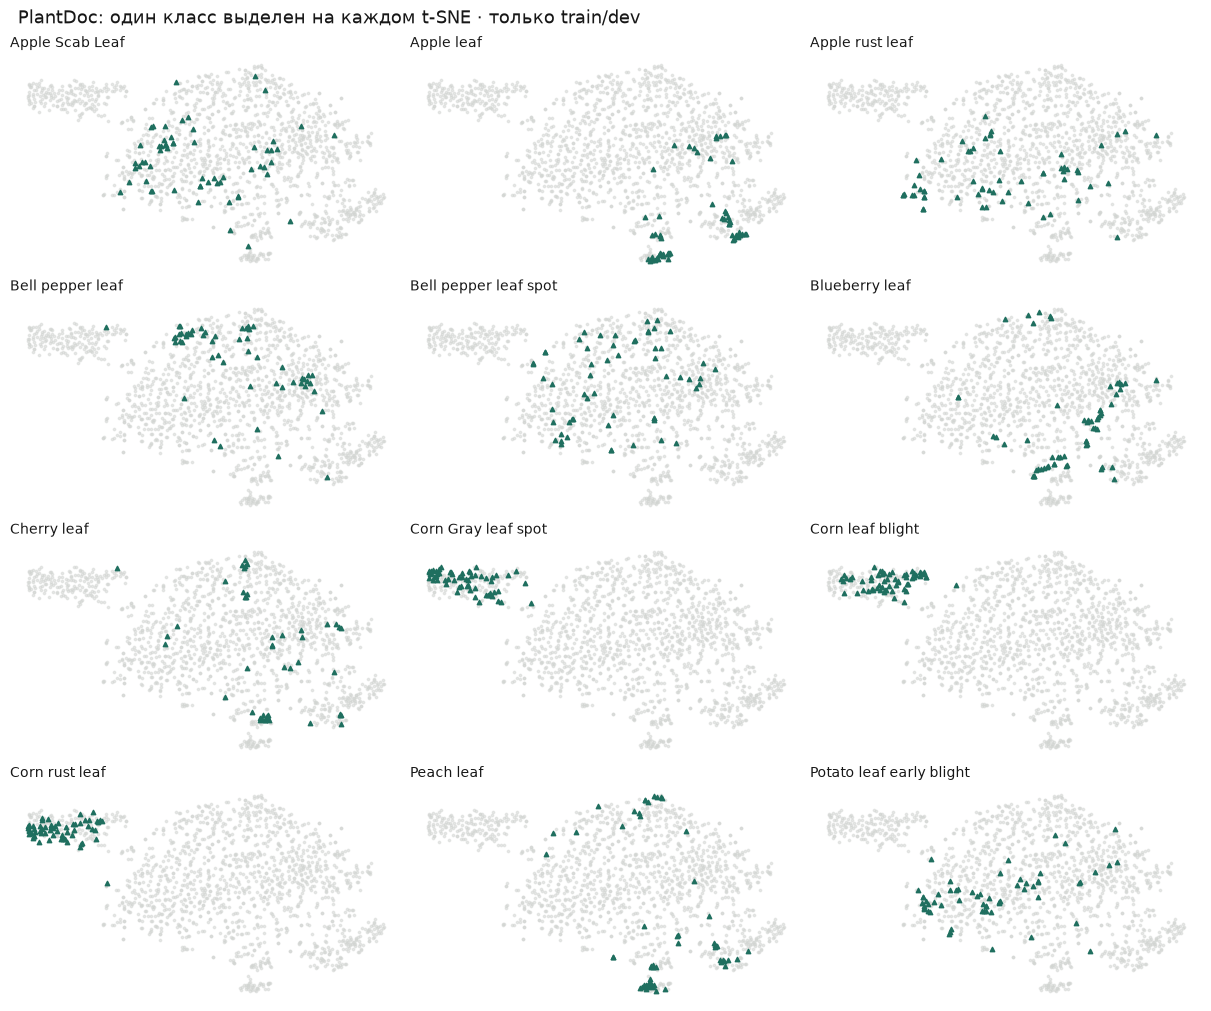

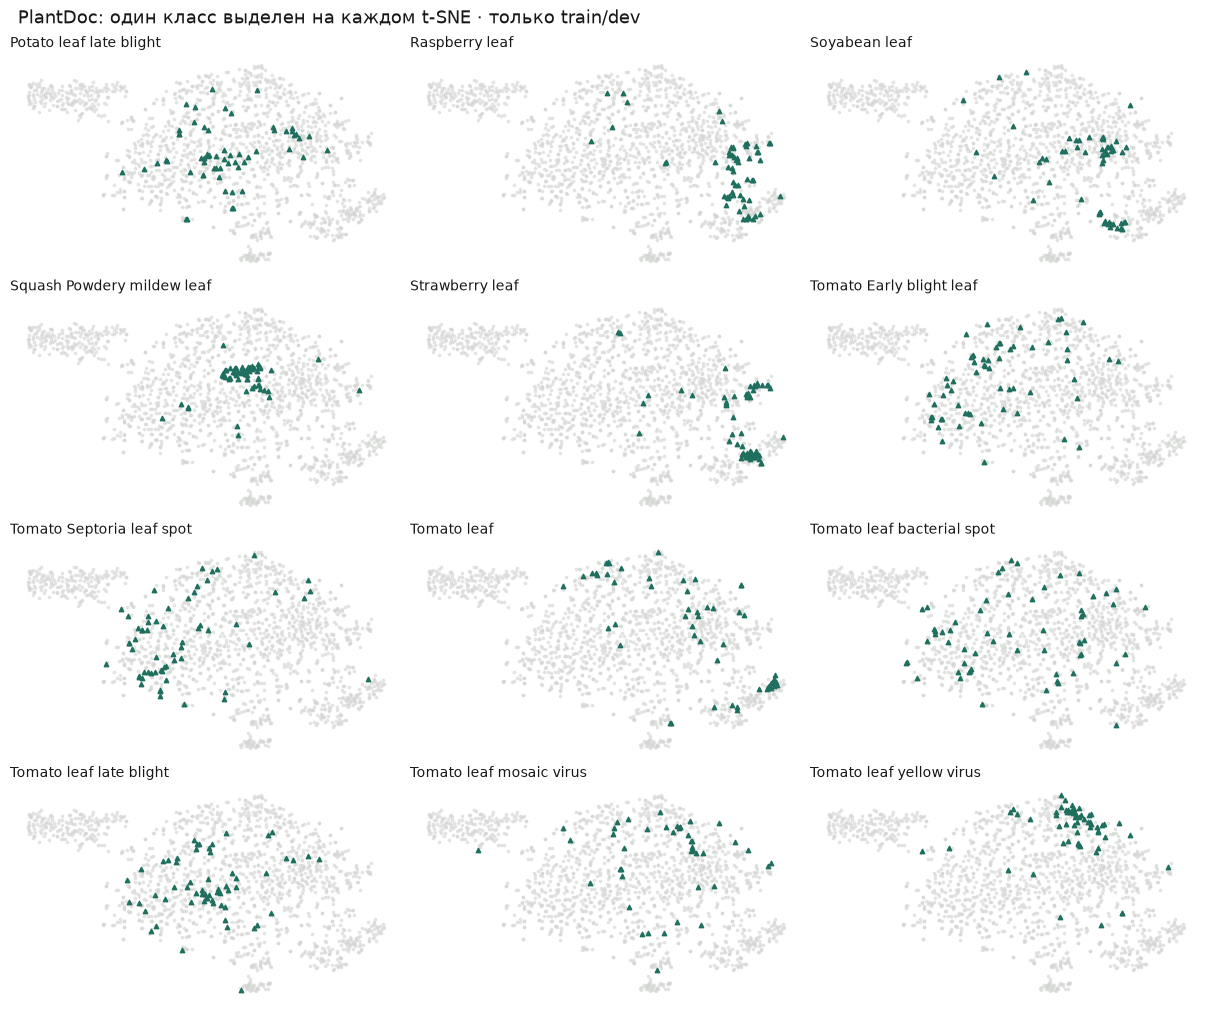

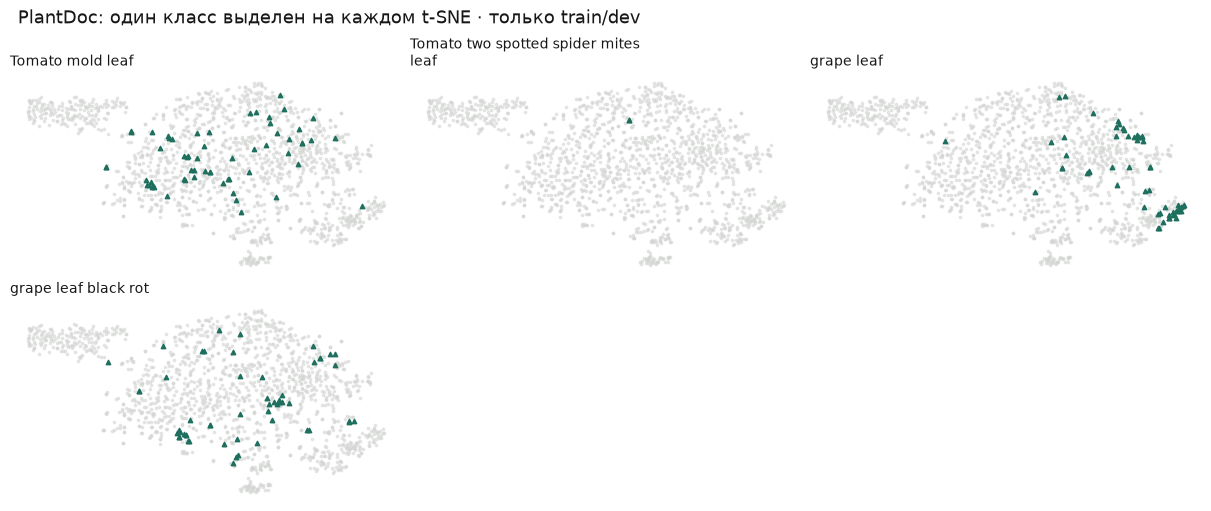

In [14]:
points = run_embeddings(force=REBUILD_EMBEDDINGS)
embedding_meta = json.loads((ROOT / 'data/processed/embedding_metadata.json').read_text())
embedding_table = pd.DataFrame(embedding_meta['metrics']).T
display(embedding_table.style.format({'n':'{:.0f}', 'classes':'{:.0f}',
    'class_silhouette_cosine_512d':'{:.4f}', 'domain_silhouette_cosine_512d':'{:.4f}'}, na_rep='—'))
plots.embedding_plots(points)

На отдельных графиках t-SNE смотрим, собираются ли фото одного класса вместе: в PlantVillage некоторые классы хорошо выделяются, в PlantDoc многие смешиваются с другими.

На общем графике снимки заметно разделяются по датасетам даже при одинаковом составе классов: готовая ResNet18 видит разницу между источниками.

Поэтому будущую модель отдельно проверим на PlantDoc

In [15]:
values = embedding_meta['metrics']
display(Markdown(
    f"**Получено:** silhouette классов в исходных эмбеддингах "
    f"PlantVillage = **{values['pv']['class_silhouette_cosine_512d']:.3f}**, "
    f"PlantDoc = **{values['pd']['class_silhouette_cosine_512d']:.3f}**. "
    f"На совместной сбалансированной выборке silhouette домена = "
    f"**{values['joint']['domain_silhouette_cosine_512d']:.3f}**. "
    "Показатели относятся только к указанным выборкам; это не результат обучения классификатора."))

**Получено:** silhouette классов в исходных эмбеддингах PlantVillage = **0.083**, PlantDoc = **-0.093**. На совместной сбалансированной выборке silhouette домена = **0.220**. Показатели относятся только к указанным выборкам; это не результат обучения классификатора.

<a id="splits"></a>
## 8. Разбиение данных

**PlantVillage:** train/val/test примерно 70/15/15, `seed=42`. Используем `StratifiedGroupKFold`: 14 из 20 частей для train, по 3 для val и test. Снимки одного листа и повторы остаются вместе.

**PlantDoc:** авторские train/test после очистки используем как `field_dev`/`field_test`. На `field_dev` подбираем улучшения, `field_test` сохраняем для итоговой оценки.

Аугментации применяем после разбиения, только к train.

In [16]:
validate_splits(df, pairs)
split_counts = pd.crosstab(df.dataset, df.split)
display(split_counts)
split_counts.to_csv(ROOT / 'reports/split_counts.csv')
pv_class_split = pd.crosstab(clean.loc[clean.dataset.eq('plantvillage'),'label'],
                             clean.loc[clean.dataset.eq('plantvillage'),'split'])
display(pv_class_split)
pv_class_split.to_csv(ROOT / 'reports/plantvillage_class_splits.csv')
primary_support = clean[clean.common_primary & clean.dataset.eq('plantdoc')].groupby('split').agg(
    images=('image_id','size'), classes=('canonical_label','nunique'))
display(primary_support)
print('Все 38 классов PlantVillage представлены в train, val и test.')
manifest_sha = hashlib.sha256((ROOT/'splits/manifest.csv').read_bytes()).hexdigest()
print('SHA-256 manifest:', manifest_sha)
split_meta = {'seed':SEED, 'plantvillage_target_ratios':[.70,.15,.15],
              'method':'StratifiedGroupKFold 20; folds 0:3 test, 3:6 val, 6:20 train',
              'phash_search_radius':6, 'threshold_calibration':calibration,
              'duplicate_decision_rule':'exact bytes/pixels OR (pHash Hamming <= 6 AND RGB MAE <= 0.035)',
              'automatic_rule_sha256':hashlib.sha256((ROOT/'scripts/duplicate_audit.py').read_bytes()).hexdigest(),
              'manifest_sha256':manifest_sha,
              'common_classes':common_labels,
              'limitation':'Leaf identity incomplete; rotated/cropped near-duplicates may remain.'}
_ = (ROOT/'splits/metadata.json').write_text(json.dumps(split_meta,ensure_ascii=False,indent=2))

split,excluded,field_dev,field_test,test,train,val
dataset,,,,,,
plantdoc,93,2252,227,0,0,0
plantvillage,69,0,0,8137,37965,8134


split,test,train,val
label,,,
Apple___Apple_scab,97,441,91
Apple___Black_rot,93,434,94
Apple___Cedar_apple_rust,40,191,44
Apple___healthy,246,1149,243
Blueberry___healthy,226,1052,224
Cherry_(including_sour)___Powdery_mildew,165,736,146
Cherry_(including_sour)___healthy,123,600,131
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,76,359,78
Corn_(maize)___Common_rust_,180,832,180


,images,classes
split,,
field_dev,1876,23
field_test,192,23


Все 38 классов PlantVillage представлены в train, val и test.
SHA-256 manifest: 93958f9bb5ef6ba801175779143f305a409ad15d376cf48e3c3fdf9e7d4e9e29


### Как будем сравнивать модели

На чекпоинте 3 пока что предлагаем **macro-F1**: она дает каждому классу одинаковый вес, что важно при дисбалансе. Сравним качество на 23 общих классах PlantVillage test и PlantDoc field_test. Настройки подбираем на val/field_dev, тест оставляем для итоговой оценки.

<a id="conclusions"></a>
## 9. Итоги

- После очистки осталось **54 236 фото PlantVillage и 2 479 PlantDoc**.
- Классы несбалансированы; для сравнения датасетов выделили **23 общих класса**.
- Фон, цвет и условия съемки различаются. На t-SNE снимки разделяются по источнику, поэтому качество модели проверим отдельно на PlantDoc.
- Сохранили разбиение с `seed=42`: PlantVillage примерно 70/15/15, PlantDoc по авторским train/test. Найденные повторы и группы одного листа остаются вместе.
- Для первого обучения выбрали мягкие аугментации: сильная обрезка и изменение цвета могут скрыть симптомы.

Дальше согласуем метрику и обучим baseline. Практическое применение описано в [PDF](reports/practical_value.pdf).

In [17]:
summary = {'raw_images':overview.images.to_dict(), 'usable_images':overview.usable_after_cleaning.to_dict(),
           'raw_classes':overview.classes.to_dict(), 'common_classes':len(common_labels),
           'exclusions':df[df.exclusion_reason.ne('')].exclusion_reason.value_counts().to_dict(),
           'split_counts':split_counts.to_dict(), 'embedding_metrics':embedding_meta['metrics'],
           'manifest_sha256':manifest_sha, 'seed':SEED}
(ROOT/'reports/eda_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
assert sum(overview.images) == len(df)
assert len(clean) + df.split.eq('excluded').sum() == len(df)
assert len(common_labels) == 23